# Trabajo parcial — Procesamiento de Imágenes
## Video de Neymar: detección automática de cambios de escena

Integrantes:
- Barrientos Villalta, Vanessa Jazmin
- Del Castillo Mendoza, Matias Javier
- Rivera Hernandez, Gabriel Omar
-



Este notebook desarrolla el trabajo completo: selección del video (1), registro manual de escenas (2), lectura, extracción de características, distancias, umbral, detección, fotogramas representativos y GIF (3.1–3.8), comparación manual vs. automática (4) y conclusiones (5).

Ejecutar las celdas de arriba hacia abajo. Los archivos se guardan en el directorio de trabajo: la raíz del proyecto al ejecutar Jupyter allí, o `/content` en Google Colab. En Colab deben descargarse los resultados antes de cerrar la sesión.

**Nota sobre el punto 2:** la tabla incluida se elaboró mediante revisión visual de imágenes a intervalos de 0,5 s a lo largo de todo el video, no mediante un detector automático. Es un registro inicial con tiempos aproximados, **pendiente de validación por el equipo mediante reproducción completa**; el muestreo puede omitir planos muy breves. No debe presentarse como un conteo humano definitivo sin esa revisión.

### Preparación del entorno
Se utiliza `gdown` para descargar desde Google Drive, OpenCV para leer el MP4 y guardar imágenes, y Pillow/Matplotlib para la revisión visual. `%pip` instala en el entorno del kernel; no se importa `google.colab.files`, para que también funcione en Jupyter local.

In [1]:
%pip install -q gdown opencv-python-headless numpy matplotlib pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\joaqu\AppData\Local\Temp\claude\C--Users-joaqu-Desktop-parcial\4caf94b6-d678-4570-809f-88561d53e7f4\scratchpad\venv\Scripts\python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import csv
import json
import math
import re
import cv2
import gdown
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image as PILImage, ImageDraw
from IPython.display import Video, display, Markdown, Image

RAIZ = Path.cwd().resolve()
ID_DRIVE = "13Hk50fmb6Kgv6-BCjES7Dz5r6Yg4Wi3K"
URL_DRIVE = f"https://drive.google.com/file/d/{ID_DRIVE}/view"
# Si el video ya está junto al notebook (neymar.mp4) se usa ese; si no, se descarga de Drive.
RUTA_VIDEO = RAIZ / "neymar.mp4" if (RAIZ / "neymar.mp4").is_file() else RAIZ / "video_op.mp4"
CARPETA_FRAMES = RAIZ / "frames_originales"
CARPETA_REVISION = RAIZ / "revision_visual"
print(f"Directorio de trabajo: {RAIZ}")

Directorio de trabajo: C:\Users\joaqu\Desktop\parcial


## 1. Selección del video

Se conserva el video de **Neymar** seleccionado por el equipo. Es una compilación de calentamiento, jugadas, regates, celebraciones y momentos con trofeos del FC Barcelona.

- **Formato:** MP4; archivo local `video_op.mp4`.
- **Fuente:** enlace de Google Drive proporcionado en el código original; se conserva el archivo descargado, sin recortar ni cambiar su resolución.
- **Duración comprobada:** aproximadamente 3 min 31 s; cumple el intervalo aproximado de 3 a 5 minutos.
- **Calidad:** 640 × 360 píxeles; permite distinguir los jugadores, el terreno y cambios de plano. Es suficiente para este ejercicio, aunque no es alta definición.
- **Cambios visuales:** contiene primeros planos, tomas generales de partidos, repeticiones desde otros ángulos y celebraciones.
- **Originalidad frente al ejemplo de clase:** debe confirmarla el equipo; no se dispone del video usado en clase para verificarlo.

La siguiente celda fija explícitamente el nombre de descarga: así OpenCV abre el mismo archivo, aunque el nombre original en Drive sea diferente.

In [3]:
# Se reutiliza el MP4 si ya está disponible. Cambiar a True para descargarlo otra vez.
FORZAR_DESCARGA = False
if FORZAR_DESCARGA or not RUTA_VIDEO.is_file() or RUTA_VIDEO.stat().st_size == 0:
    ruta_temporal = RAIZ / "video_op.descarga.mp4"
    resultado = gdown.download(id=ID_DRIVE, output=str(ruta_temporal), quiet=False)
    if resultado is None or not ruta_temporal.is_file() or ruta_temporal.stat().st_size == 0:
        raise RuntimeError("No se pudo descargar el video. Verificar el ID y los permisos de Drive.")
    prueba = cv2.VideoCapture(str(ruta_temporal))
    try:
        legible, _ = prueba.read()
        if not prueba.isOpened() or not legible:
            raise RuntimeError("La descarga no es un video legible. Revisar el archivo de Drive.")
    finally:
        prueba.release()
    ruta_temporal.replace(RUTA_VIDEO)
else:
    print("Se reutiliza el video local; no se vuelve a descargar.")
print(f"Archivo: {RUTA_VIDEO.name} ({RUTA_VIDEO.stat().st_size / 1024**2:.2f} MiB)")
display(Markdown(f"[Abrir el video original en Google Drive]({URL_DRIVE})"))

Se reutiliza el video local; no se vuelve a descargar.
Archivo: neymar.mp4 (17.25 MiB)


[Abrir el video original en Google Drive](https://drive.google.com/file/d/13Hk50fmb6Kgv6-BCjES7Dz5r6Yg4Wi3K/view)

In [4]:
cap = cv2.VideoCapture(str(RUTA_VIDEO))
try:
    if not cap.isOpened():
        raise RuntimeError(f"OpenCV no puede abrir {RUTA_VIDEO.name}.")
    fps = float(cap.get(cv2.CAP_PROP_FPS))
    ancho = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    alto = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames_declarado = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if not math.isfinite(fps) or fps <= 0 or min(ancho, alto, total_frames_declarado) <= 0:
        raise RuntimeError("El video no tiene metadatos válidos para esta lectura.")
    duracion_s = total_frames_declarado / fps
finally:
    cap.release()

def tiempo_texto(segundos):
    """Representación MM:SS.s; conserva décimas en los límites aproximados."""
    decimas = round(float(segundos) * 10)
    minutos, resto = divmod(decimas, 600)
    segundos_enteros, decimal = divmod(resto, 10)
    return f"{minutos:02d}:{segundos_enteros:02d}.{decimal}"

print(f"Duración: {tiempo_texto(duracion_s)} ({duracion_s:.3f} s)")
print(f"¿Duración dentro de 3–5 minutos?: {'Sí' if 180 <= duracion_s <= 300 else 'No; revisar selección'}")

Duración: 03:31.5 (211.467 s)
¿Duración dentro de 3–5 minutos?: Sí


### Reproducción para validar el registro manual
Reproducir **todo** el video y revisar cada corte, pausando o reduciendo la velocidad cuando sea necesario. El reproductor local usa el archivo sin incrustar sus 18 MB en el notebook. Si no reproduce en Colab o el navegador no reconoce el códec, usar el enlace de Drive de arriba o abrir `video_op.mp4` en un reproductor local.

In [5]:
display(Video(str(RUTA_VIDEO), embed=False, width=min(ancho, 640)))

## 2. Identificación manual de escenas — registro visual inicial

**Criterio de segmentación:** se registra un nuevo segmento cuando se observa un corte de edición a otro clip o un cambio de cámara/plano claramente diferenciado, incluidas repeticiones de una misma jugada. No se considera nueva escena cada movimiento de Neymar, del balón o cada desplazamiento/zoom continuo de la cámara. Este criterio debe mantenerse cuando se compare con el método automático.

**Procedencia y precisión:** revisión visual de láminas tomadas cada 0,5 s; los límites son aproximados, generalmente dentro del intervalo entre dos imágenes revisadas. No se calcularon histogramas, distancias ni umbrales para construir esta tabla. El conteo es provisional: puede cambiar después de la reproducción completa por el equipo.

La lista editable contiene el inicio, en segundos, y la descripción de cada segmento. El final se obtiene del inicio del siguiente segmento; el último termina al finalizar el video. Los intervalos son `[inicio, final)`, sin huecos ni solapamientos. La primera escena empieza en cero y **no** representa un cambio de escena.

In [6]:
# Anotaciones visuales iniciales. Ajustar después de revisar el video completo.
# Cada fila corresponde a un plano/clip visual, no a una escena detectada por código.
escenas_anotadas = [
    (0.0, "Neymar durante el calentamiento, con chaqueta negra y franjas azules."),
    (8.5, "Neymar con camiseta del Barcelona, mirando y señalando hacia arriba."),
    (11.5, "Primer plano de Neymar mirando al cielo."),
    (13.0, "Primer plano de Neymar mirando al frente y bajando la mirada."),
    (14.5, "Neymar se lleva las manos a la cabeza y se cubre el rostro."),
    (16.5, "Regate junto a la banda con camiseta amarilla y roja, frente a un defensor de blanco."),
    (19.5, "Otro plano de la misma acción cerca del área y la portería."),
    (22.0, "Plano general de un ataque del Barcelona ante rivales de blanco y celeste."),
    (29.0, "Plano cercano del regate junto a la línea de fondo ante un defensor celeste."),
    (32.0, "Neymar intenta superar a defensores de camiseta gris y termina cayendo."),
    (34.0, "Plano general de un ataque y remate ante el mismo equipo de gris."),
    (42.0, "Neymar celebra corriendo con los brazos abiertos hacia la tribuna."),
    (48.0, "Neymar y sus compañeros posan para una fotografía con un teléfono en el campo."),
    (54.5, "Neymar levanta una copa junto a sus compañeros y fotógrafos."),
    (59.5, "Plano general de una llegada al área ante un equipo de amarillo."),
    (61.5, "Repetición a nivel de campo de la acción frente al equipo amarillo."),
    (63.5, "Repetición desde detrás de la portería."),
    (65.0, "Plano general de una nueva jugada junto al área, ante rivales claros."),
    (67.0, "Regate cercano frente a un defensor con camiseta de franjas blancas y negras."),
    (69.0, "Regate cerca de la banda ante un defensor de blanco con franjas azules."),
    (71.0, "Detalle de los pies y del balón en esa jugada junto a la banda."),
    (72.5, "Plano general de una jugada ante rivales con camiseta amarilla y pantalón azul."),
    (75.0, "Plano cercano del control y regate frente a esos rivales."),
    (76.5, "Plano general de un partido con Neymar vestido de amarillo y rivales celestes."),
    (78.0, "Repetición cercana del control del balón ante un defensor celeste."),
    (80.0, "Neymar con uniforme rojo supera a defensores de franjas azules y blancas."),
    (83.5, "Plano general de una conducción y caída frente a rivales de franjas rojas y blancas."),
    (91.0, "Nueva jugada ofensiva ante rivales de franjas rojas y blancas, con remate al arco."),
    (96.5, "Neymar regatea por la banda ante defensores de franjas azules y blancas."),
    (102.0, "Otra secuencia de regate ante ese equipo, desde un plano general."),
    (105.0, "Ataque del Barcelona ante un equipo claro con detalles verdes y remate a portería."),
    (110.0, "Breve plano general de otra acción junto a la banda frente a rivales de blanco y verde."),
    (110.5, "Plano a nivel de campo del regate ante un defensor de blanco y verde."),
    (114.5, "Plano cercano de una disputa del balón ante jugadores de celeste."),
    (116.5, "Neymar controla un balón aéreo y avanza junto a la publicidad de Champions League."),
    (121.5, "Plano general de un regate junto a la línea lateral ante un rival de blanco."),
    (124.0, "Repetición cercana del mismo regate y control del balón."),
    (125.5, "Nueva conducción por la banda ante un defensor de uniforme claro."),
    (128.5, "Otra acción cerca del área frente a varios jugadores de blanco."),
    (130.0, "Plano cercano de Neymar elevando el balón y superando a defensores de blanco."),
    (135.0, "Plano general de una conducción larga entre rivales claros hacia el área."),
    (143.5, "Nueva jugada junto a la banda, con tribuna y publicidad BBVA al fondo."),
    (147.5, "Plano general de otro regate frente a un equipo con camiseta blanca."),
    (153.0, "Neymar de amarillo conduce entre rivales de rojo y blanco y termina cayendo."),
    (160.0, "Neymar de rojo avanza y regatea ante un equipo de azul."),
    (166.5, "Nueva conducción y caída ante jugadores de blanco, desde un plano general."),
    (173.5, "Detalle de los pies y el balón frente a un defensor de uniforme claro."),
    (175.0, "Plano general de una acción del Barcelona ante rivales de amarillo."),
    (179.5, "Regate a nivel de campo frente a defensores de franjas blancas y negras."),
    (181.5, "Plano general de un ataque y gol ante el equipo de franjas blancas y negras."),
    (188.0, "Celebración de Neymar y sus compañeros frente a la tribuna."),
    (193.5, "Neymar arrodillado sobre el césped, con una cinta blanca en la cabeza."),
    (197.5, "Neymar y compañeros posan junto a una gran copa de Champions League."),
    (201.0, "Fotografía grupal de jugadores con trofeo y una bandera de Brasil."),
    (206.5, "Neymar abraza a un compañero con la bandera de Brasil y luego saluda en el campo."),
]

inicios = [inicio for inicio, _ in escenas_anotadas]
if not inicios or inicios[0] != 0 or any(b <= a for a, b in zip(inicios, inicios[1:])):
    raise ValueError("Los inicios deben partir de cero y estar ordenados sin duplicados.")
if inicios[-1] >= duracion_s:
    raise ValueError("El video no coincide con la anotación: revisar los tiempos y la fuente.")

escenas = []
for i, (inicio, descripcion) in enumerate(escenas_anotadas):
    fin = inicios[i + 1] if i + 1 < len(inicios) else duracion_s
    escenas.append({"escena": i + 1, "inicio_s": inicio, "fin_s": fin,
                    "tiempo_inicial": tiempo_texto(inicio), "tiempo_final": tiempo_texto(fin),
                    "descripcion": descripcion})

assert math.isclose(sum(e["fin_s"] - e["inicio_s"] for e in escenas), duracion_s)
lineas = ["| Escena | Tiempo inicial | Tiempo final | Descripción |", "|---:|:---:|:---:|---|"]
lineas += [f'| {e["escena"]} | {e["tiempo_inicial"]} | {e["tiempo_final"]} | {e["descripcion"]} |' for e in escenas]
display(Markdown("\n".join(lineas)))
print(f"Total del registro visual inicial: {len(escenas)} escenas; {len(escenas) - 1} cambios.")
print("Estado: pendiente de validación humana mediante reproducción completa.")

with (RAIZ / "escenas_manuales.csv").open("w", encoding="utf-8-sig", newline="") as archivo:
    escritor = csv.DictWriter(archivo, fieldnames=list(escenas[0]))
    escritor.writeheader()
    escritor.writerows(escenas)
print("Tabla exportada: escenas_manuales.csv")

| Escena | Tiempo inicial | Tiempo final | Descripción |
|---:|:---:|:---:|---|
| 1 | 00:00.0 | 00:08.5 | Neymar durante el calentamiento, con chaqueta negra y franjas azules. |
| 2 | 00:08.5 | 00:11.5 | Neymar con camiseta del Barcelona, mirando y señalando hacia arriba. |
| 3 | 00:11.5 | 00:13.0 | Primer plano de Neymar mirando al cielo. |
| 4 | 00:13.0 | 00:14.5 | Primer plano de Neymar mirando al frente y bajando la mirada. |
| 5 | 00:14.5 | 00:16.5 | Neymar se lleva las manos a la cabeza y se cubre el rostro. |
| 6 | 00:16.5 | 00:19.5 | Regate junto a la banda con camiseta amarilla y roja, frente a un defensor de blanco. |
| 7 | 00:19.5 | 00:22.0 | Otro plano de la misma acción cerca del área y la portería. |
| 8 | 00:22.0 | 00:29.0 | Plano general de un ataque del Barcelona ante rivales de blanco y celeste. |
| 9 | 00:29.0 | 00:32.0 | Plano cercano del regate junto a la línea de fondo ante un defensor celeste. |
| 10 | 00:32.0 | 00:34.0 | Neymar intenta superar a defensores de camiseta gris y termina cayendo. |
| 11 | 00:34.0 | 00:42.0 | Plano general de un ataque y remate ante el mismo equipo de gris. |
| 12 | 00:42.0 | 00:48.0 | Neymar celebra corriendo con los brazos abiertos hacia la tribuna. |
| 13 | 00:48.0 | 00:54.5 | Neymar y sus compañeros posan para una fotografía con un teléfono en el campo. |
| 14 | 00:54.5 | 00:59.5 | Neymar levanta una copa junto a sus compañeros y fotógrafos. |
| 15 | 00:59.5 | 01:01.5 | Plano general de una llegada al área ante un equipo de amarillo. |
| 16 | 01:01.5 | 01:03.5 | Repetición a nivel de campo de la acción frente al equipo amarillo. |
| 17 | 01:03.5 | 01:05.0 | Repetición desde detrás de la portería. |
| 18 | 01:05.0 | 01:07.0 | Plano general de una nueva jugada junto al área, ante rivales claros. |
| 19 | 01:07.0 | 01:09.0 | Regate cercano frente a un defensor con camiseta de franjas blancas y negras. |
| 20 | 01:09.0 | 01:11.0 | Regate cerca de la banda ante un defensor de blanco con franjas azules. |
| 21 | 01:11.0 | 01:12.5 | Detalle de los pies y del balón en esa jugada junto a la banda. |
| 22 | 01:12.5 | 01:15.0 | Plano general de una jugada ante rivales con camiseta amarilla y pantalón azul. |
| 23 | 01:15.0 | 01:16.5 | Plano cercano del control y regate frente a esos rivales. |
| 24 | 01:16.5 | 01:18.0 | Plano general de un partido con Neymar vestido de amarillo y rivales celestes. |
| 25 | 01:18.0 | 01:20.0 | Repetición cercana del control del balón ante un defensor celeste. |
| 26 | 01:20.0 | 01:23.5 | Neymar con uniforme rojo supera a defensores de franjas azules y blancas. |
| 27 | 01:23.5 | 01:31.0 | Plano general de una conducción y caída frente a rivales de franjas rojas y blancas. |
| 28 | 01:31.0 | 01:36.5 | Nueva jugada ofensiva ante rivales de franjas rojas y blancas, con remate al arco. |
| 29 | 01:36.5 | 01:42.0 | Neymar regatea por la banda ante defensores de franjas azules y blancas. |
| 30 | 01:42.0 | 01:45.0 | Otra secuencia de regate ante ese equipo, desde un plano general. |
| 31 | 01:45.0 | 01:50.0 | Ataque del Barcelona ante un equipo claro con detalles verdes y remate a portería. |
| 32 | 01:50.0 | 01:50.5 | Breve plano general de otra acción junto a la banda frente a rivales de blanco y verde. |
| 33 | 01:50.5 | 01:54.5 | Plano a nivel de campo del regate ante un defensor de blanco y verde. |
| 34 | 01:54.5 | 01:56.5 | Plano cercano de una disputa del balón ante jugadores de celeste. |
| 35 | 01:56.5 | 02:01.5 | Neymar controla un balón aéreo y avanza junto a la publicidad de Champions League. |
| 36 | 02:01.5 | 02:04.0 | Plano general de un regate junto a la línea lateral ante un rival de blanco. |
| 37 | 02:04.0 | 02:05.5 | Repetición cercana del mismo regate y control del balón. |
| 38 | 02:05.5 | 02:08.5 | Nueva conducción por la banda ante un defensor de uniforme claro. |
| 39 | 02:08.5 | 02:10.0 | Otra acción cerca del área frente a varios jugadores de blanco. |
| 40 | 02:10.0 | 02:15.0 | Plano cercano de Neymar elevando el balón y superando a defensores de blanco. |
| 41 | 02:15.0 | 02:23.5 | Plano general de una conducción larga entre rivales claros hacia el área. |
| 42 | 02:23.5 | 02:27.5 | Nueva jugada junto a la banda, con tribuna y publicidad BBVA al fondo. |
| 43 | 02:27.5 | 02:33.0 | Plano general de otro regate frente a un equipo con camiseta blanca. |
| 44 | 02:33.0 | 02:40.0 | Neymar de amarillo conduce entre rivales de rojo y blanco y termina cayendo. |
| 45 | 02:40.0 | 02:46.5 | Neymar de rojo avanza y regatea ante un equipo de azul. |
| 46 | 02:46.5 | 02:53.5 | Nueva conducción y caída ante jugadores de blanco, desde un plano general. |
| 47 | 02:53.5 | 02:55.0 | Detalle de los pies y el balón frente a un defensor de uniforme claro. |
| 48 | 02:55.0 | 02:59.5 | Plano general de una acción del Barcelona ante rivales de amarillo. |
| 49 | 02:59.5 | 03:01.5 | Regate a nivel de campo frente a defensores de franjas blancas y negras. |
| 50 | 03:01.5 | 03:08.0 | Plano general de un ataque y gol ante el equipo de franjas blancas y negras. |
| 51 | 03:08.0 | 03:13.5 | Celebración de Neymar y sus compañeros frente a la tribuna. |
| 52 | 03:13.5 | 03:17.5 | Neymar arrodillado sobre el césped, con una cinta blanca en la cabeza. |
| 53 | 03:17.5 | 03:21.0 | Neymar y compañeros posan junto a una gran copa de Champions League. |
| 54 | 03:21.0 | 03:26.5 | Fotografía grupal de jugadores con trofeo y una bandera de Brasil. |
| 55 | 03:26.5 | 03:31.5 | Neymar abraza a un compañero con la bandera de Brasil y luego saluda en el campo. |

Total del registro visual inicial: 55 escenas; 54 cambios.
Estado: pendiente de validación humana mediante reproducción completa.
Tabla exportada: escenas_manuales.csv


### Evidencia y apoyo a la revisión visual
Las siguientes láminas recorren todo el video a intervalos de 0,5 s y muestran el tiempo en segundos. Sirven para localizar los cambios y documentar la revisión visual; **no reemplazan la reproducción completa ni garantizan encontrar cortes más breves que el intervalo**. El muestreo se usa solo para visualizar: en 3.1 se almacenan **todos** los fotogramas, sin saltos.

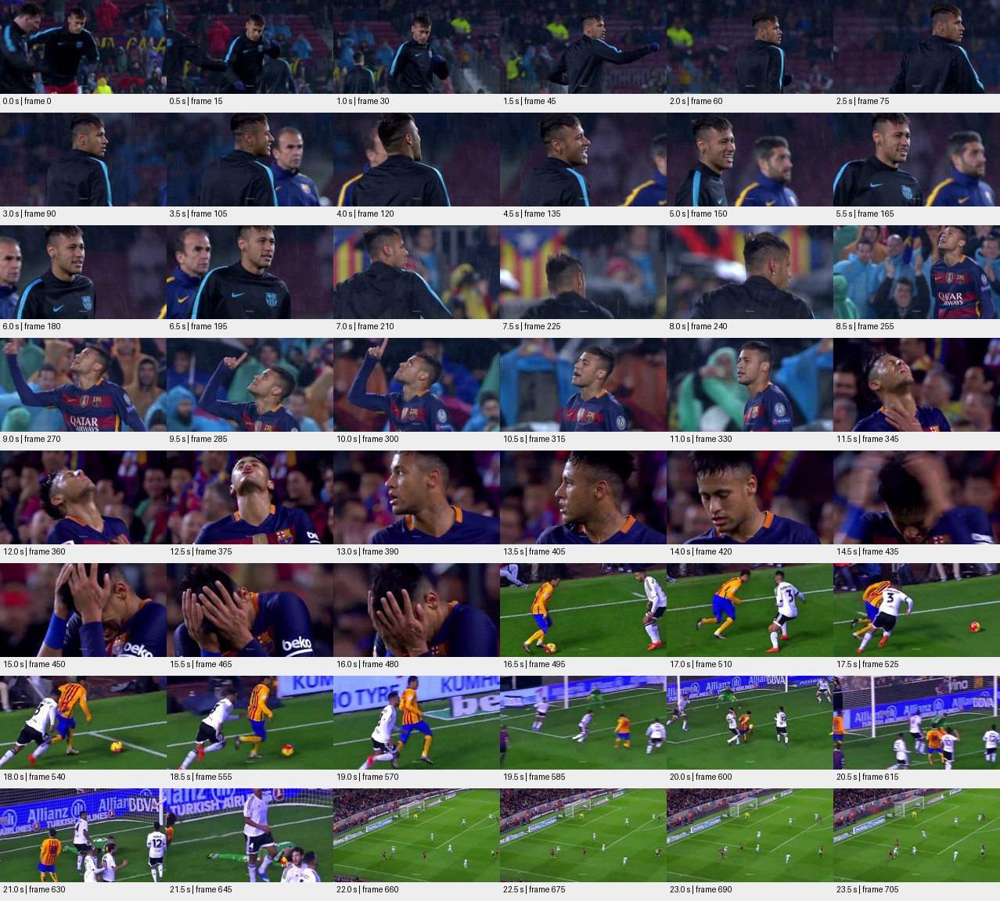

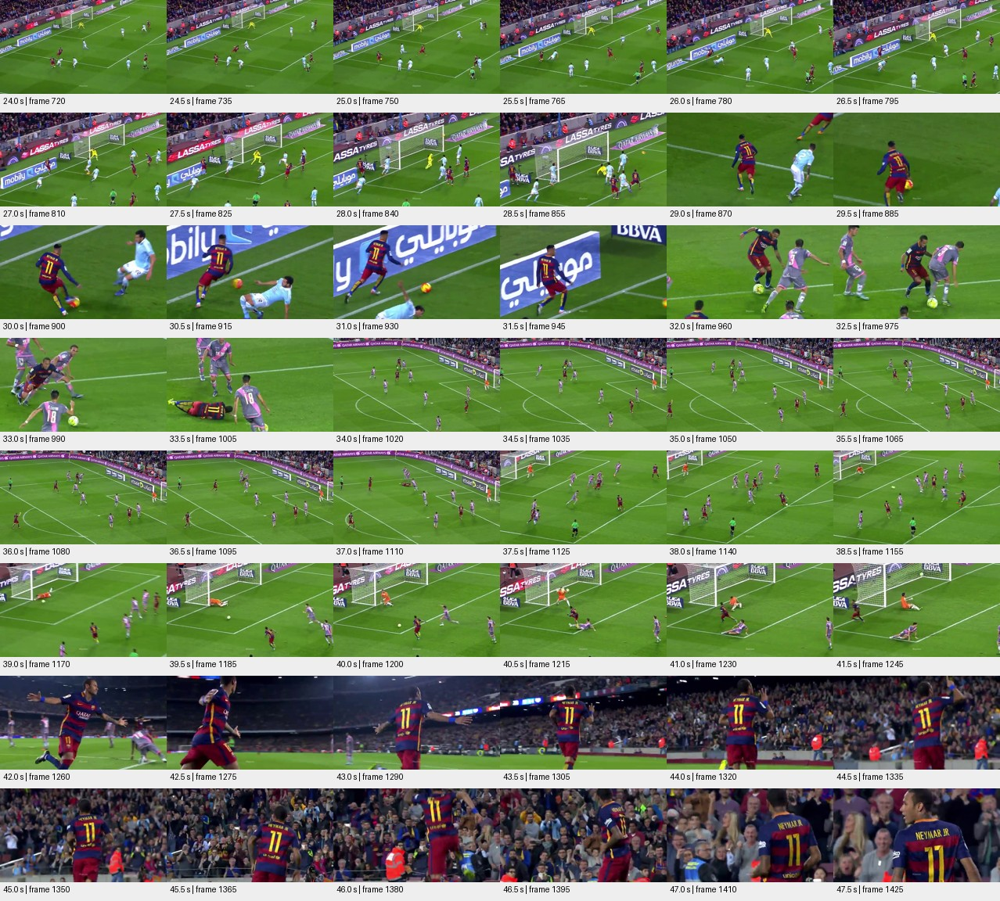

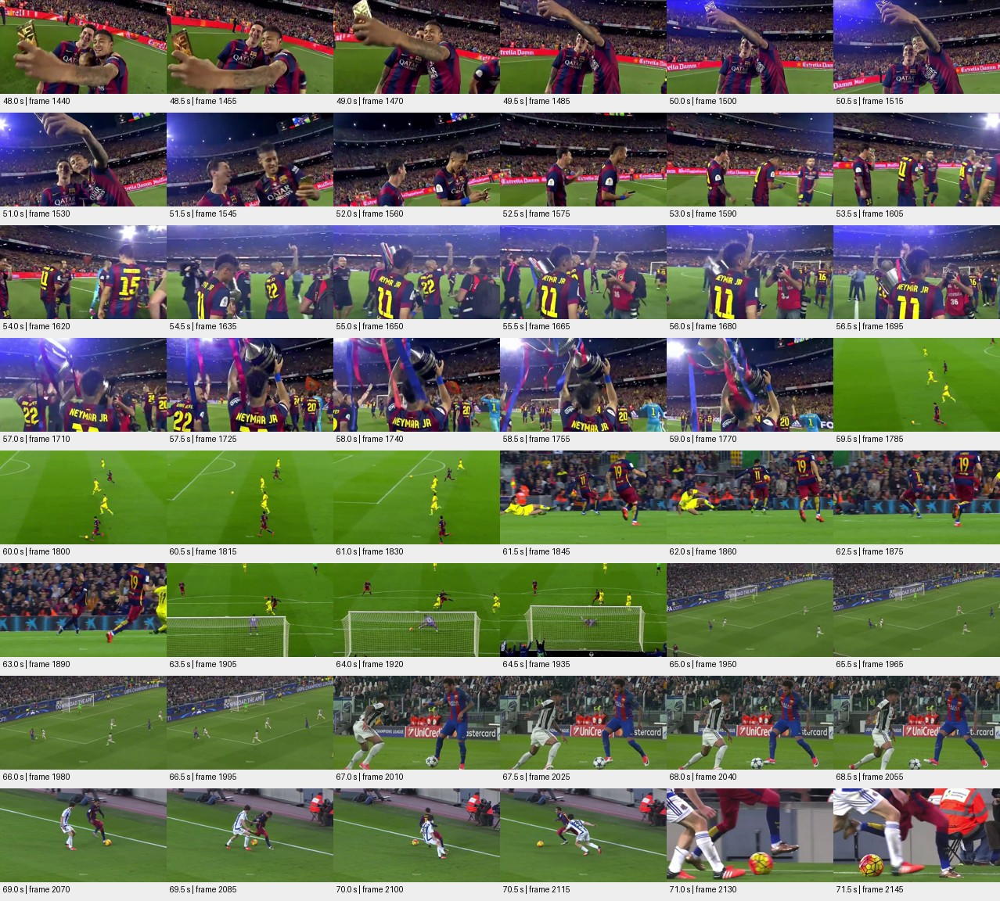

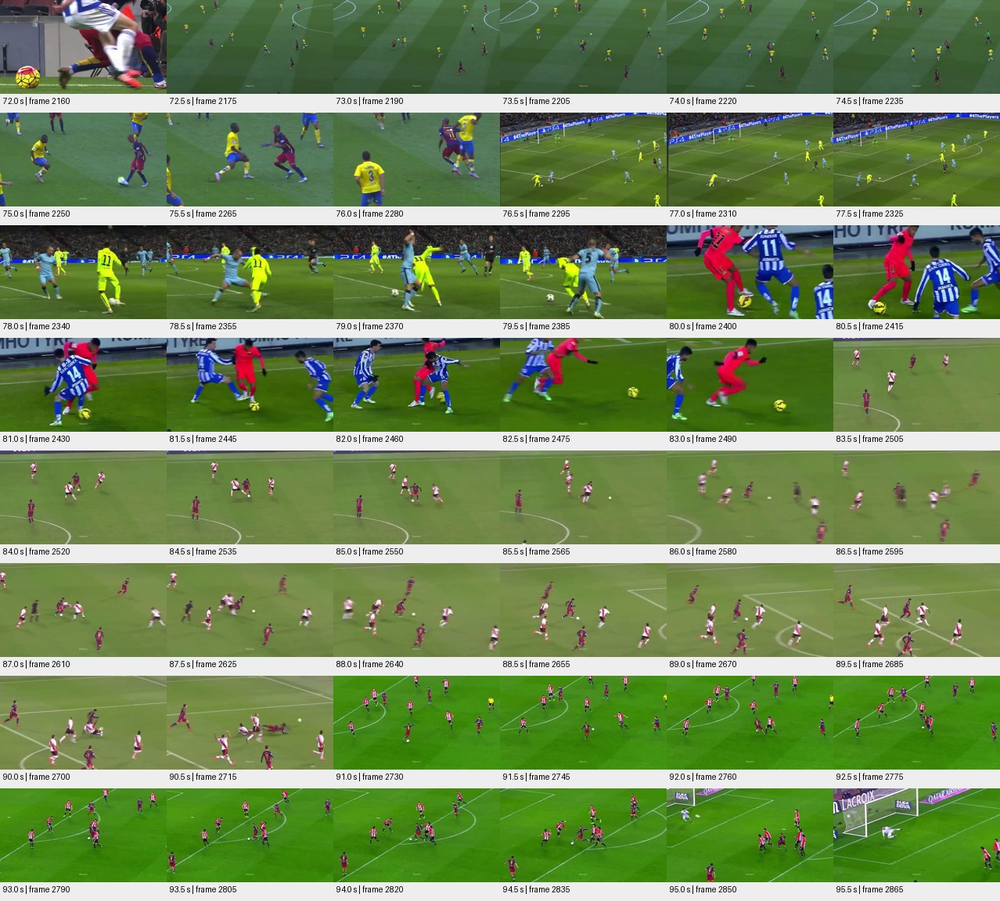

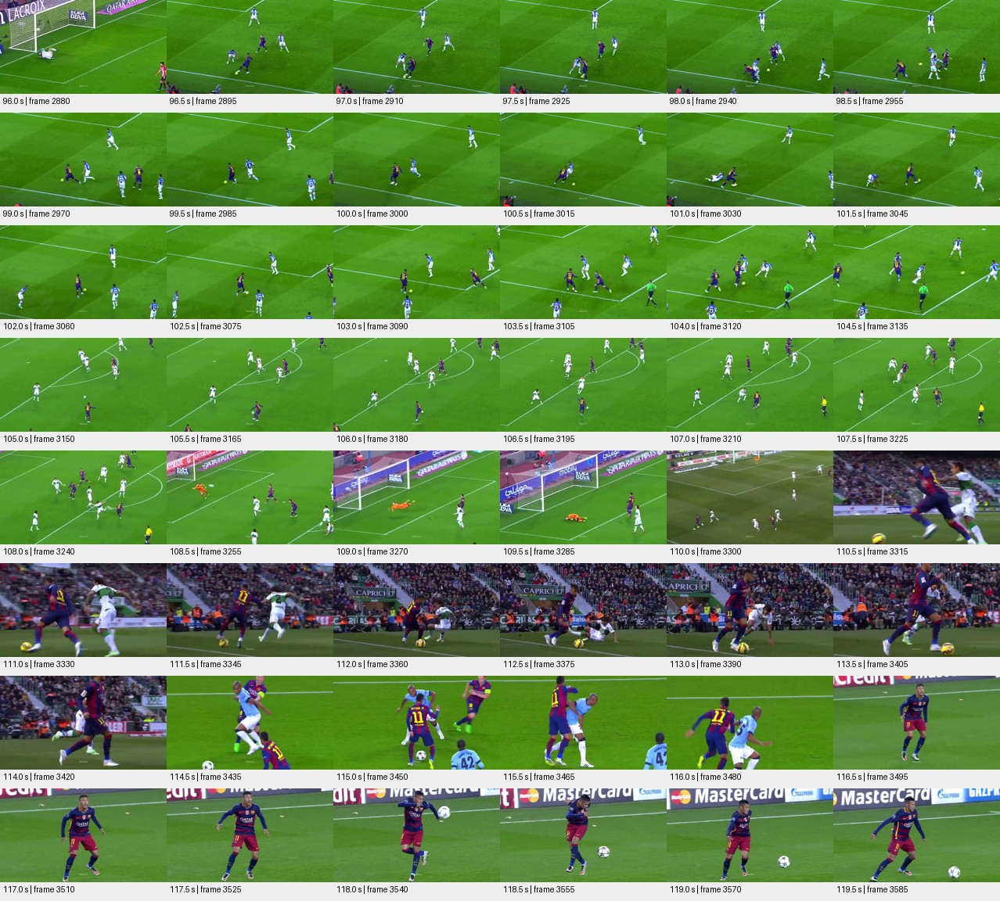

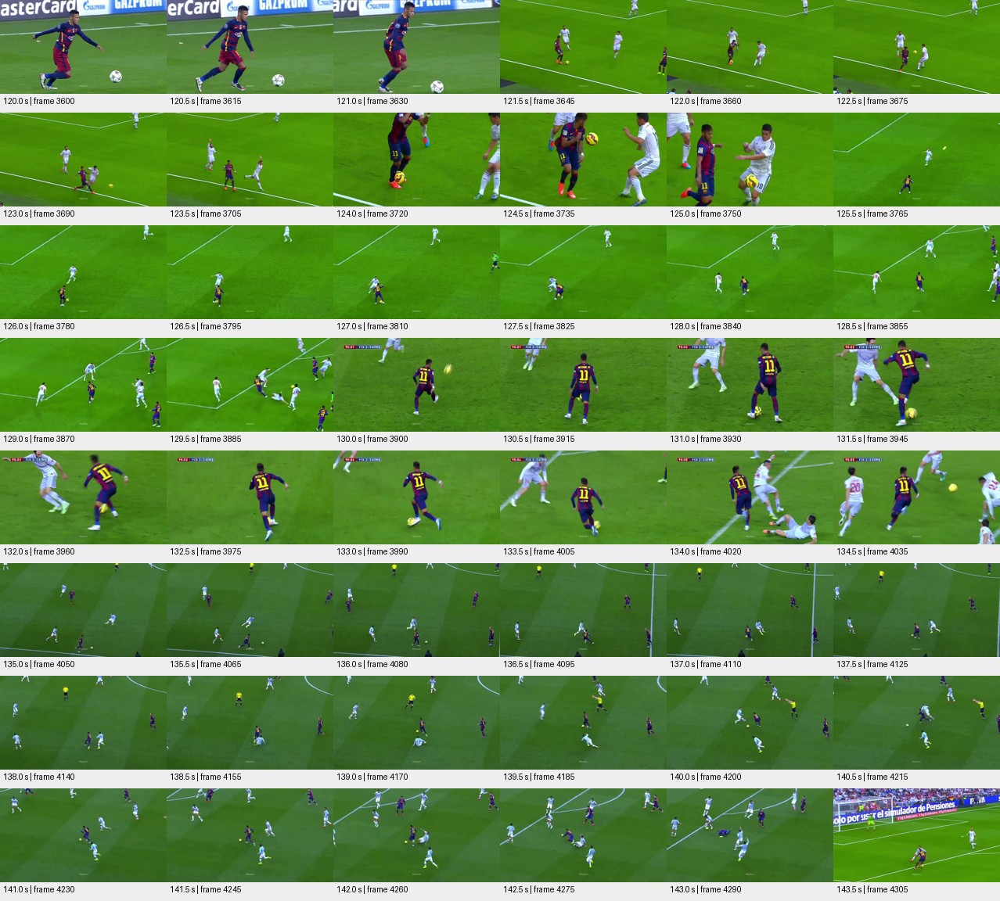

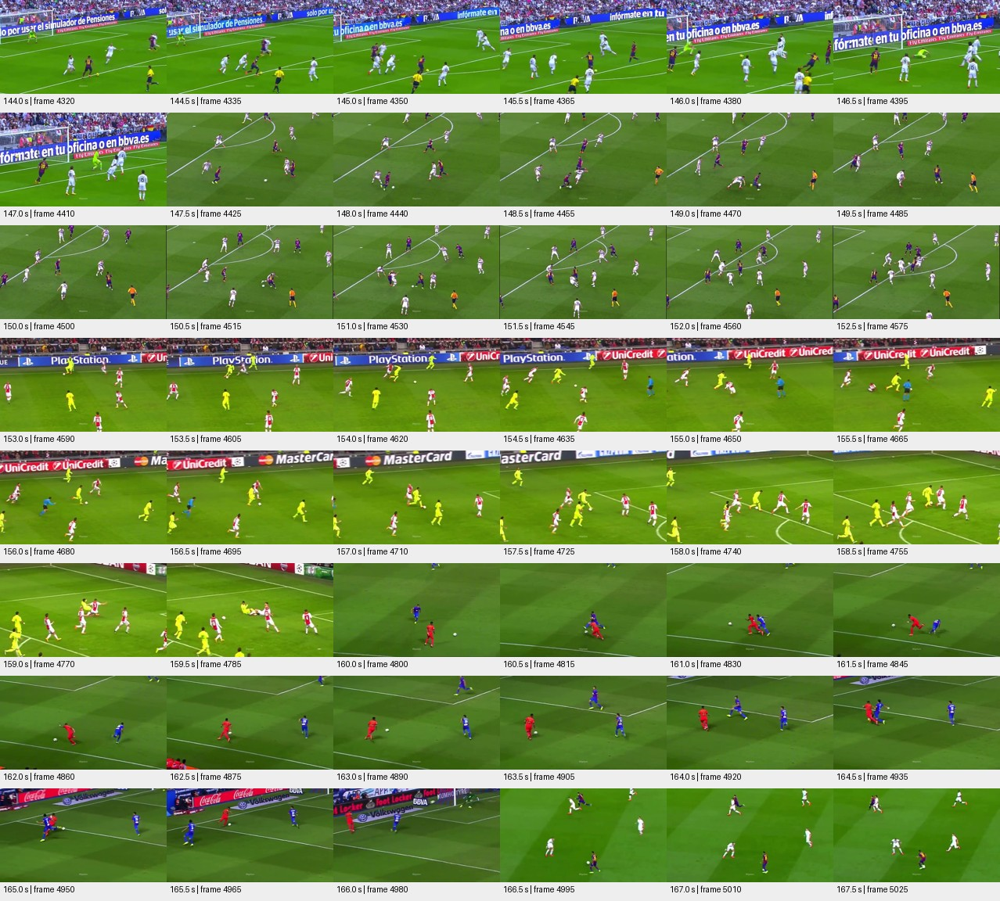

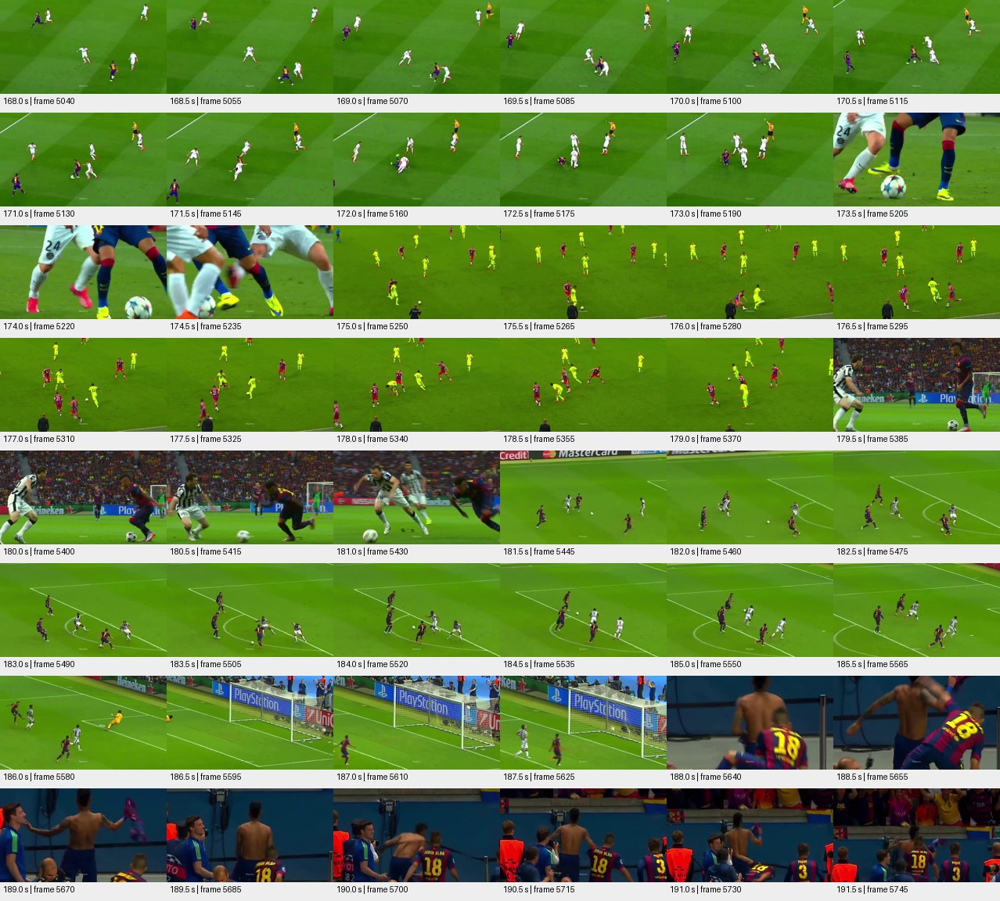

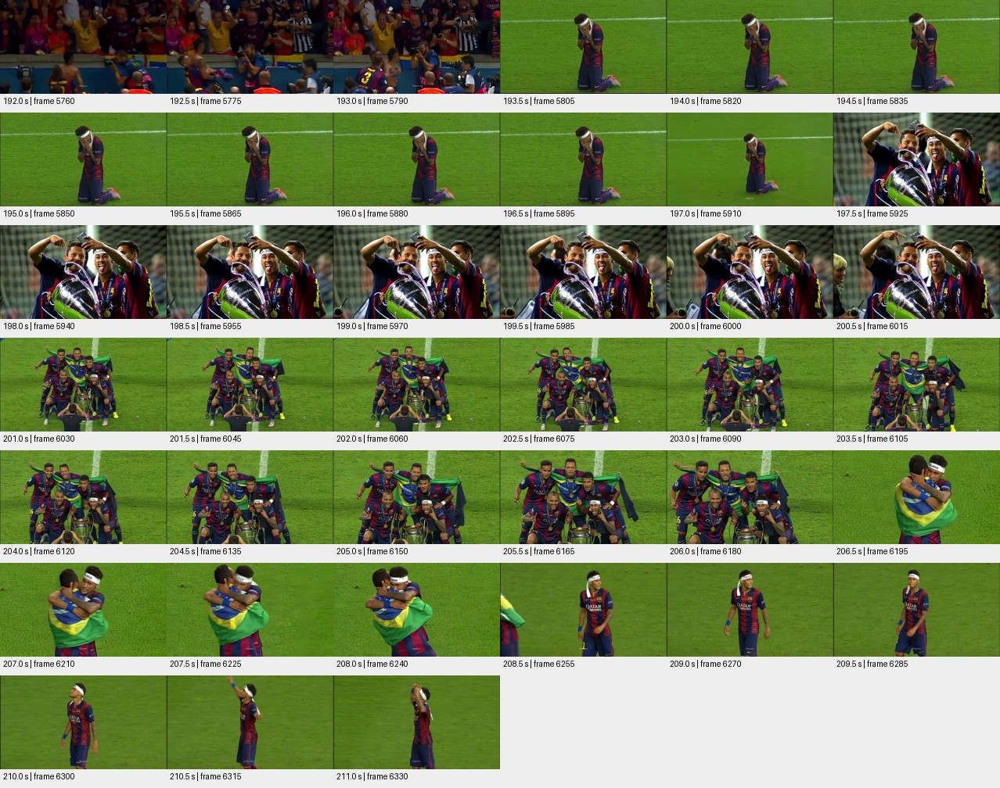

In [7]:
CARPETA_REVISION.mkdir(exist_ok=True)
INTERVALO_REVISION_S = 0.5
MINIATURAS_POR_LAMINA = 48
COLUMNAS = 6
ANCHO_MINIATURA, ALTO_MINIATURA = 213, 120
ALTO_CELDA = 144
indices_revision = list(range(0, total_frames_declarado, round(fps * INTERVALO_REVISION_S)))
cap = cv2.VideoCapture(str(RUTA_VIDEO))
try:
    if not cap.isOpened():
        raise RuntimeError("No se pudo abrir el video para la revisión visual.")
    for inicio in range(0, len(indices_revision), MINIATURAS_POR_LAMINA):
        grupo = indices_revision[inicio:inicio + MINIATURAS_POR_LAMINA]
        filas = math.ceil(len(grupo) / COLUMNAS)
        lamina = PILImage.new("RGB", (COLUMNAS * ANCHO_MINIATURA, filas * ALTO_CELDA), "#eeeeee")
        dibujo = ImageDraw.Draw(lamina)
        for j, indice in enumerate(grupo):
            cap.set(cv2.CAP_PROP_POS_FRAMES, indice)
            ok, frame = cap.read()
            if not ok:
                raise RuntimeError(f"No se pudo revisar el fotograma {indice}.")
            miniatura = PILImage.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            miniatura = miniatura.resize((ANCHO_MINIATURA, ALTO_MINIATURA))
            x, y = (j % COLUMNAS) * ANCHO_MINIATURA, (j // COLUMNAS) * ALTO_CELDA
            lamina.paste(miniatura, (x, y))
            dibujo.text((x + 4, y + ALTO_MINIATURA + 3), f"{indice / fps:.1f} s | frame {indice}", fill="black")
        ruta = CARPETA_REVISION / f"lamina_{inicio // MINIATURAS_POR_LAMINA + 1:02d}.jpg"
        lamina.save(ruta, quality=90)
        display(Image(filename=str(ruta)))
finally:
    cap.release()

## 3. Desarrollo en notebook
### 3.1. Lectura del video y extracción de fotogramas

OpenCV abre el MP4 con `VideoCapture`. `read()` decodifica sucesivamente cada fotograma y `imwrite()` lo guarda en `frames_originales`, conservando su tamaño y sus tres canales de color. No se redimensiona, convierte a grises ni realiza preprocesamiento para características.

Se utiliza **JPEG con calidad 95**, manteniendo el formato del código de referencia y reduciendo el espacio en disco. JPEG tiene compresión con pérdida: los fotogramas no son copias sin pérdida de los píxeles decodificados; esta decisión debe mantenerse en el análisis posterior. La extracción puede tardar y necesita cientos de MB libres.

- Nombres: `frame_00000.jpg`, `frame_00001.jpg`, etc. La numeración empieza en **0** y coincide con el índice de OpenCV.
- Tiempo aproximado: `indice / fps`, adecuado para este video con tasa de 30 FPS. No representa timestamps exactos para un video con tasa variable.
- Cantidad declarada: metadatos del MP4. Cantidad extraída: contador de lecturas y escrituras exitosas; se contrasta con los metadatos y se avisa si difieren, sin inventar imágenes faltantes.
- Duración aproximada: `cantidad / fps`. El tiempo del último fotograma es `(cantidad - 1) / fps`, no el final del video.

Se libera la captura con `finally` incluso si ocurre un error y se verifica el resultado de cada escritura. Al repetir la extracción se sobrescriben los archivos propios; únicamente se eliminan sobrantes con el patrón exacto `frame_XXXXX.jpg`, sin borrar la carpeta completa ni archivos ajenos.

In [8]:
CARPETA_FRAMES.mkdir(exist_ok=True)
RUTA_INDICE = RAIZ / "indice_fotogramas.csv"
indice_temporal = RAIZ / "indice_fotogramas.tmp.csv"
cap = cv2.VideoCapture(str(RUTA_VIDEO))
contador = 0
try:
    if not cap.isOpened():
        raise RuntimeError("No se pudo abrir el video para extraer sus fotogramas.")
    with indice_temporal.open("w", encoding="utf-8", newline="") as archivo:
        escritor = csv.writer(archivo)
        escritor.writerow(["fotograma", "tiempo_s", "ruta"])
        while True:
            ret, frame = cap.read()
            if not ret:
                break
            if frame.shape != (alto, ancho, 3):
                raise RuntimeError(f"Dimensiones inesperadas en el fotograma {contador}: {frame.shape}")
            ruta = CARPETA_FRAMES / f"frame_{contador:05d}.jpg"
            guardado = cv2.imwrite(str(ruta), frame, [cv2.IMWRITE_JPEG_QUALITY, 95])
            if not guardado:
                raise OSError(f"No se pudo guardar {ruta}. Revisar espacio y permisos.")
            escritor.writerow([contador, f"{contador / fps:.6f}", ruta.relative_to(RAIZ).as_posix()])
            contador += 1
            if contador % 1000 == 0:
                print(f"Guardados {contador}/{total_frames_declarado} fotogramas...")
finally:
    cap.release()

if contador == 0:
    raise RuntimeError("No se extrajo ningún fotograma.")
diferencia_frames = total_frames_declarado - contador
if diferencia_frames != 0:
    print(f"ADVERTENCIA: el MP4 declara {total_frames_declarado} fotogramas, pero OpenCV decodificó {contador}.")
    print("read() terminó: puede existir una diferencia de metadatos o un problema de decodificación.")
    print("Se guardan todos los fotogramas legibles; no se rellenan ni se duplican los faltantes.")
    # En este archivo se observan dos fotogramas de diferencia, menos de 0,1 s.
    # Una diferencia grande exige revisar la fuente antes de seguir.
    if abs(diferencia_frames) > max(2, round(fps * 0.1)):
        raise RuntimeError("Diferencia superior a 0,1 s: revisar el video o el decodificador.")

# Limpiar únicamente sobrantes propios después de recorrer todo lo decodificable.
for ruta in CARPETA_FRAMES.iterdir():
    coincidencia = re.fullmatch(r"frame_(\d{5,})\.jpg", ruta.name)
    if ruta.is_file() and coincidencia and int(coincidencia.group(1)) >= contador:
        ruta.unlink()
indice_temporal.replace(RUTA_INDICE)

archivos_frames = [p for p in CARPETA_FRAMES.iterdir() if p.is_file() and re.fullmatch(r"frame_\d{5,}\.jpg", p.name)]
if len(archivos_frames) != contador:
    raise RuntimeError("El número de imágenes guardadas no coincide con el contador.")

metadatos = {
    "video": RUTA_VIDEO.name, "drive_id": ID_DRIVE,
    "fps": fps, "ancho": ancho, "alto": alto,
    "fotogramas_declarados": total_frames_declarado, "fotogramas_extraidos": contador,
    "diferencia_fotogramas": diferencia_frames,
    "duracion_segun_metadatos_s": duracion_s,
    "duracion_aproximada_s": contador / fps,
    "carpeta_fotogramas": CARPETA_FRAMES.name,
    "formato_fotogramas": "JPEG", "calidad_jpeg": 95, "indice_inicial": 0,
    "escenas_registro_visual_inicial": len(escenas),
    "estado_registro_manual": "pendiente de validación humana mediante reproducción completa",
    "intervalo_revision_visual_s": INTERVALO_REVISION_S,
}
(RAIZ / "metadatos_video.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=2), encoding="utf-8")

resumen = f"""| Característica | Resultado |
|---|---:|
| Cantidad total de fotogramas (MP4) | {total_frames_declarado} |
| Fotogramas extraídos y guardados | {contador} |
| Diferencia (declarados − extraídos) | {diferencia_frames} |
| FPS | {fps:.2f} |
| Resolución (ancho × alto) | {ancho} × {alto} píxeles |
| Duración aproximada | {tiempo_texto(contador / fps)} ({contador / fps:.3f} s) |
| Índice del último fotograma | {contador - 1} |
| Espacio de los JPEG | {sum(p.stat().st_size for p in archivos_frames) / 1024**2:.1f} MiB |
"""
display(Markdown(resumen))
print(f"Carpeta: {CARPETA_FRAMES}")
print("Archivos auxiliares: indice_fotogramas.csv y metadatos_video.json")

Guardados 1000/6344 fotogramas...


Guardados 2000/6344 fotogramas...


Guardados 3000/6344 fotogramas...


Guardados 4000/6344 fotogramas...


Guardados 5000/6344 fotogramas...


Guardados 6000/6344 fotogramas...


ADVERTENCIA: el MP4 declara 6344 fotogramas, pero OpenCV decodificó 6342.
read() terminó: puede existir una diferencia de metadatos o un problema de decodificación.
Se guardan todos los fotogramas legibles; no se rellenan ni se duplican los faltantes.


| Característica | Resultado |
|---|---:|
| Cantidad total de fotogramas (MP4) | 6344 |
| Fotogramas extraídos y guardados | 6342 |
| Diferencia (declarados − extraídos) | 2 |
| FPS | 30.00 |
| Resolución (ancho × alto) | 640 × 360 píxeles |
| Duración aproximada | 03:31.4 (211.400 s) |
| Índice del último fotograma | 6341 |
| Espacio de los JPEG | 323.5 MiB |


Carpeta: C:\Users\joaqu\Desktop\parcial\frames_originales
Archivos auxiliares: indice_fotogramas.csv y metadatos_video.json


### Comprobación visual de la extracción
Se reabren los JPEG del inicio, mitad y final para comprobar su lectura, color y dimensiones. OpenCV trabaja en BGR; para mostrarlos correctamente en Matplotlib se convierten a RGB. Esta es una comprobación de almacenamiento, **no** la selección automática de fotogramas representativos del punto 3.7.

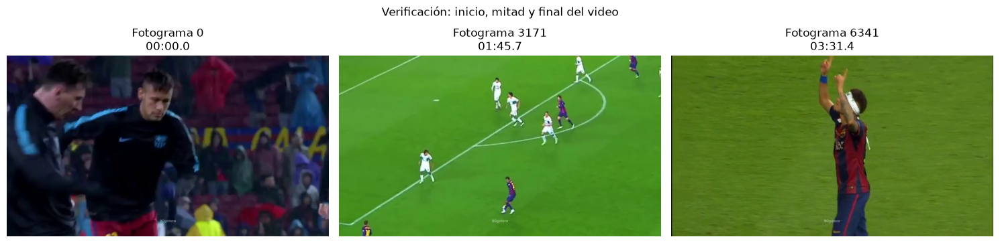

In [9]:
indices_muestra = [0, contador // 2, contador - 1]
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, indice in zip(ejes, indices_muestra):
    ruta = CARPETA_FRAMES / f"frame_{indice:05d}.jpg"
    imagen = cv2.imread(str(ruta))
    if imagen is None or imagen.shape != (alto, ancho, 3):
        raise RuntimeError(f"El JPEG {ruta.name} no se puede leer o tiene dimensiones incorrectas.")
    eje.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
    eje.set_title(f"Fotograma {indice}\n{tiempo_texto(indice / fps)}")
    eje.axis("off")
fig.suptitle("Verificación: inicio, mitad y final del video")
plt.tight_layout()
plt.show()

### Resultado y modificaciones frente al código de referencia

Se conservan el ID de Drive, el nombre `video_op.mp4`, OpenCV y la estructura de nombres de los JPEG. Se agregan:

1. Descarga con nombre de salida explícito, validación del MP4 y reutilización del archivo local.
2. Celdas Markdown organizadas según los puntos del enunciado y registro visual editable de escenas, con su limitación metodológica expresada.
3. Duración aproximada, validación de FPS y contraste entre fotogramas declarados y realmente guardados.
4. Manejo seguro de recursos, comprobación de cada escritura y limpieza limitada a sobrantes propios.
5. CSV de escenas, índice de fotogramas, metadatos JSON y comprobación visual de las imágenes guardadas.

**Observación real de la extracción:** el MP4 declara 6344 fotogramas, mientras OpenCV decodifica y guarda 6342 (211,400 s frente a 211,467 s según los metadatos). La diferencia de dos fotogramas equivale a aproximadamente 0,067 s. Se informa explícitamente: no se fabrican imágenes para alcanzar el contador declarado y se usan los 6342 JPEG legibles para los puntos posteriores. Sin una inspección adicional del contenedor/decodificador no se atribuye una causa definitiva a la diferencia.

No se crea `frames_procesados` todavía: ese directorio correspondería a etapas posteriores que no están incluidas en este alcance. El siguiente paso del equipo es **validar el registro manual viendo el video completo** y, posteriormente, desarrollar 3.2 usando los fotogramas extraídos.

## 3.2. Extracción de características

Utilizar un método de comparación con histogramas de cada fotograma o un método
propuesto visto en clase. Se deberá:



*   Realizar el preprocesamiento correspondiente.
*   Extraer un vector de características para cada fotograma.


El estudiante deberá explicar brevemente qué representa este vector de


características y por
qué puede utilizarse para comparar imágenes


In [10]:
print("Extrayendo histogramas HSV... (Esto tomará unos segundos)")

cap = cv2.VideoCapture(str(RUTA_VIDEO))
caracteristicas = []

while True:
    ret, frame = cap.read()
    if not ret:
        break

    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

    hist = cv2.calcHist([hsv], [0], None, [64], [0, 180])

    #histograma a un rango de 0 a 1
    cv2.normalize(hist, hist, alpha=0, beta=1, norm_type=cv2.NORM_MINMAX)

    caracteristicas.append(hist.flatten())

cap.release()

# Integración: se convierte la lista en una matriz NumPy (una fila por fotograma),
# porque las secciones 3.5-3.7 usan operaciones de arrays (mean, slicing, etc.).
caracteristicas = np.array(caracteristicas)
print(f"¡Listo! Se extrajeron los vectores de características de {len(caracteristicas)} fotogramas.")
print(f"Matriz de características: {caracteristicas.shape}")

Extrayendo histogramas HSV... (Esto tomará unos segundos)


¡Listo! Se extrajeron los vectores de características de 6342 fotogramas.
Matriz de características: (6342, 64)


## 3.3. Comparación entre fotogramas consecutivos

Implementar la distancia coseno para comparar las características de cada par de
fotogramas consecutivos:

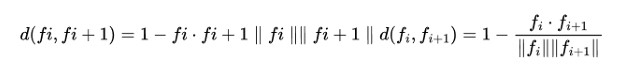

Calcular la distancia entre:






● Fotograma 1 y fotograma 2.

● Fotograma 2 y fotograma 3.

● Fotograma 3 y fotograma 4.

● Y así sucesivamente hasta finalizar el video.

Explicar brevemente:
● Qué significa obtener una distancia cercana a 0.

● Qué significa obtener una distancia relativamente alta.

● Por qué una distancia elevada podría representar un cambio de escena.

In [11]:
distancias = []
print("Calculando distancias coseno...")

for i in range(len(caracteristicas) - 1):
    f_i = caracteristicas[i]
    f_next = caracteristicas[i + 1]

    # Numerador: Producto punto
    dot_product = np.dot(f_i, f_next)

    # Denominador: Multiplicación de las magnitudes (normas)
    norm_i = np.linalg.norm(f_i)
    norm_next = np.linalg.norm(f_next)

    if norm_i == 0 or norm_next == 0:
        d = 0.0
    else:
        d = 1.0 - (dot_product / (norm_i * norm_next))

    distancias.append(d)

# Integración: se convierte a array NumPy para poder usar distancias.mean(), distancias > umbral, etc.
distancias = np.array(distancias)

print(f"¡Listo! Se obtuvieron {len(distancias)} distancias calculadas.")

Calculando distancias coseno...
¡Listo! Se obtuvieron 6341 distancias calculadas.


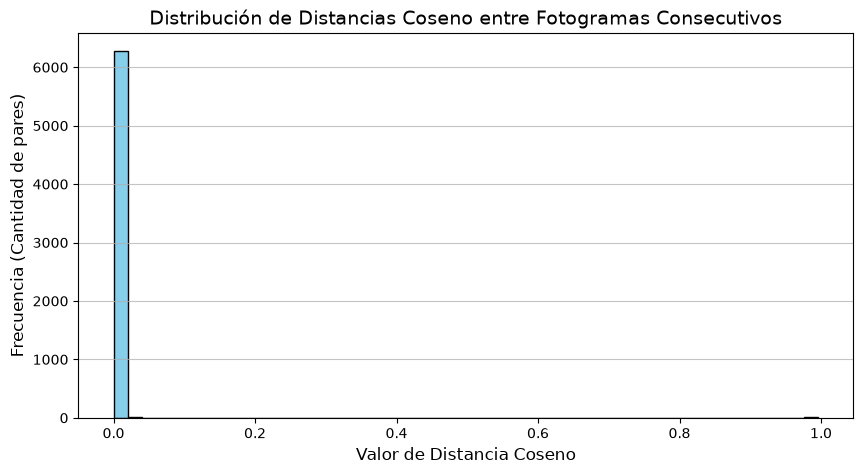

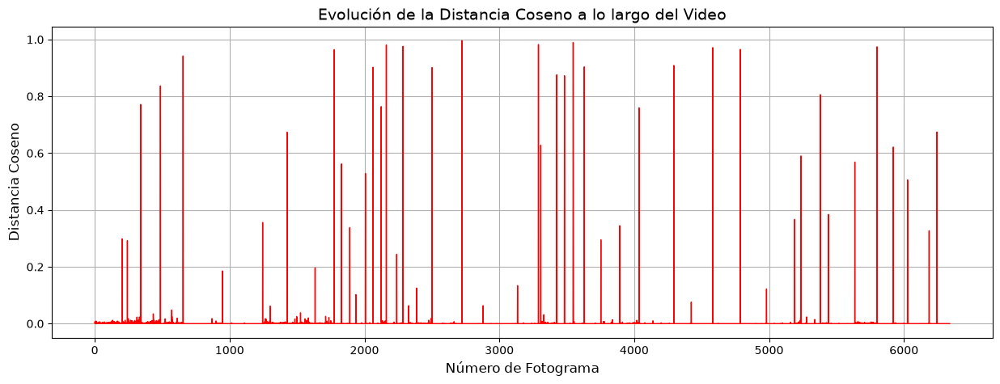

In [12]:
# 3.4 ANÁLISIS DE LAS DISTANCIAS

# a. Histograma de distancias
plt.figure(figsize=(10, 5))
plt.hist(distancias, bins=50, color='skyblue', edgecolor='black')
plt.title('Distribución de Distancias Coseno entre Fotogramas Consecutivos', fontsize=14)
plt.xlabel('Valor de Distancia Coseno', fontsize=12)
plt.ylabel('Frecuencia (Cantidad de pares)', fontsize=12)
plt.grid(axis='y', alpha=0.75)
plt.show()

# b. Grafico de distancia por fotograma
plt.figure(figsize=(15, 5))
plt.plot(distancias, color='red', linewidth=1)
plt.title('Evolución de la Distancia Coseno a lo largo del Video', fontsize=14)
plt.xlabel('Número de Fotograma', fontsize=12)
plt.ylabel('Distancia Coseno', fontsize=12)
plt.grid(True)
plt.show()

### 3.5. Determinación del umbral

Un **umbral** convierte la serie continua de distancias en una decisión binaria: si `distancias[i] > umbral`, se considera que entre los fotogramas `i` e `i + 1` hay un posible cambio de escena, y el **cambio se ubica en el fotograma `i + 1`** (el primero de la nueva escena). Con `k` cambios se obtienen `k + 1` escenas.

**Dos decisiones adicionales y su justificación:**

1. **Supresión de no máximos (separación mínima de 0,33 s ≈ 10 fotogramas).** Un corte limpio produce un solo pico, pero un fundido, un destello de cámara o un movimiento brusco producen *varios* valores altos seguidos. Sin esta regla, una sola transición se contaría como varias escenas. Dentro de cada ventana se conserva solo el pico de mayor distancia. El valor de 0,33 s es menor que la escena manual más corta del registro (0,5 s), por lo que no impide detectar planos breves reales.
2. **Evaluación objetiva contra el registro manual.** Contar escenas no basta: un umbral puede acertar el *número* total con cambios en lugares equivocados (falsos positivos que compensan omisiones). Por eso cada cambio automático se empareja, uno a uno, con un cambio manual si ambos están a **≤ 0,75 s**. La tolerancia se justifica porque los límites manuales se obtuvieron con láminas cada 0,5 s: el corte real puede estar hasta 0,5 s antes del tiempo anotado.

Con ese emparejamiento se calcula:

| Medida | Significado |
|---|---|
| **VP** (verdaderos positivos) | Cambios automáticos que coinciden con un cambio manual. |
| **FP** (falsos cambios) | Cambios automáticos sin correspondencia manual: el algoritmo “corta” donde no hay nueva escena. |
| **FN** (no detectados) | Cambios manuales que el algoritmo no encontró. |
| **Precisión** = VP / (VP + FP) | Qué proporción de lo detectado es correcto. |
| **Recall** = VP / (VP + FN) | Qué proporción de los cambios reales se encontró. |
| **F1** | Media armónica de precisión y recall; resume el equilibrio entre ambos. |

In [13]:
SEPARACION_MIN_S = 0.33
TOLERANCIA_S = 0.75
SEPARACION_MIN = max(1, round(fps * SEPARACION_MIN_S))
TOLERANCIA = max(1, round(fps * TOLERANCIA_S))

if len(distancias) != contador - 1:
    raise RuntimeError("`distancias` debe tener contador - 1 elementos (pares consecutivos).")

# Cambios de referencia: inicio de cada escena manual excepto la primera, en fotogramas.
cambios_manual = np.array([round(e["inicio_s"] * fps) for e in escenas[1:]], dtype=int)
escenas_manual = len(escenas)

def detectar_cambios(distancias, umbral, separacion=SEPARACION_MIN):
    # Devuelve los fotogramas (i + 1) donde empieza una nueva escena.
    candidatos = np.flatnonzero(distancias > umbral)
    candidatos = candidatos[np.argsort(distancias[candidatos])[::-1]]   # picos más altos primero
    bloqueado = np.zeros(len(distancias), dtype=bool)
    aceptados = []
    for i in candidatos:
        if not bloqueado[i]:
            aceptados.append(i)
            bloqueado[max(0, i - separacion + 1): i + separacion] = True
    return np.sort(np.array(aceptados, dtype=int)) + 1

def comparar_con_manual(cambios_auto, cambios_ref=cambios_manual, tolerancia=TOLERANCIA):
    # Emparejamiento uno a uno, priorizando los pares más cercanos en el tiempo.
    pares = sorted((abs(int(a) - int(m)), ia, im)
                   for ia, a in enumerate(cambios_auto)
                   for im, m in enumerate(cambios_ref) if abs(int(a) - int(m)) <= tolerancia)
    usados_a, usados_m = set(), set()
    for _, ia, im in pares:
        if ia not in usados_a and im not in usados_m:
            usados_a.add(ia); usados_m.add(im)
    vp = len(usados_a)
    fp, fn = len(cambios_auto) - vp, len(cambios_ref) - vp
    precision = vp / (vp + fp) if vp + fp else 0.0
    recall = vp / (vp + fn) if vp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"vp": vp, "fp": fp, "fn": fn, "precision": precision, "recall": recall, "f1": f1,
            "falsos": [int(a) for ia, a in enumerate(cambios_auto) if ia not in usados_a],
            "omitidos": [im for im in range(len(cambios_ref)) if im not in usados_m]}

print(f"Separación mínima entre cambios: {SEPARACION_MIN} fotogramas ({SEPARACION_MIN / fps:.2f} s)")
print(f"Tolerancia de coincidencia: ±{TOLERANCIA} fotogramas (±{TOLERANCIA / fps:.2f} s)")
print(f"Referencia manual: {escenas_manual} escenas, {len(cambios_manual)} cambios")

Separación mínima entre cambios: 10 fotogramas (0.33 s)
Tolerancia de coincidencia: ±22 fotogramas (±0.73 s)
Referencia manual: 55 escenas, 54 cambios


#### Experimento con tres umbrales fijos y uno estadístico

Se prueban los tres valores sugeridos (0,10; 0,20; 0,30) y, como cuarto candidato, un **umbral estadístico** que se adapta al video: `media + 3·desviación estándar` de las distancias. La mayoría de pares consecutivos pertenece a la misma escena, así que la distribución está dominada por valores pequeños; un valor que se aleja tres desviaciones de la media es atípico y es candidato a corte.

In [14]:
umbral_estadistico = float(distancias.mean() + 3 * distancias.std())
UMBRALES = [0.10, 0.20, 0.30, round(umbral_estadistico, 3)]

resultados = {}
for umbral in UMBRALES:
    cambios = detectar_cambios(distancias, umbral)
    resultados[umbral] = {"cambios": cambios, "escenas": len(cambios) + 1, **comparar_con_manual(cambios)}

filas = ["| Umbral | Escenas detectadas | Diferencia vs. manual | VP | FP (falsos) | FN (omitidos) | Precisión | Recall | F1 |",
         "|---:|---:|---:|---:|---:|---:|---:|---:|---:|"]
for umbral, r in resultados.items():
    etiqueta = f"{umbral:.3f} (estadístico)" if umbral == UMBRALES[-1] else f"{umbral:.2f}"
    filas.append(f"| {etiqueta} | {r['escenas']} | {r['escenas'] - escenas_manual:+d} | {r['vp']} | {r['fp']} | {r['fn']} "
                 f"| {r['precision']:.2f} | {r['recall']:.2f} | {r['f1']:.2f} |")
display(Markdown(f"**Conteo manual de referencia: {escenas_manual} escenas.**\n\n" + "\n".join(filas)))

**Conteo manual de referencia: 55 escenas.**

| Umbral | Escenas detectadas | Diferencia vs. manual | VP | FP (falsos) | FN (omitidos) | Precisión | Recall | F1 |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 0.10 | 47 | -8 | 43 | 3 | 11 | 0.93 | 0.80 | 0.86 |
| 0.20 | 41 | -14 | 37 | 3 | 17 | 0.93 | 0.69 | 0.79 |
| 0.30 | 37 | -18 | 34 | 2 | 20 | 0.94 | 0.63 | 0.76 |
| 0.185 (estadístico) | 43 | -12 | 39 | 3 | 15 | 0.93 | 0.72 | 0.81 |

#### Observaciones por umbral: falsos cambios y escenas no detectadas

Para cada umbral se listan ejemplos concretos. Los **falsos cambios** muestran su tiempo y su distancia; las **escenas no detectadas** muestran la descripción manual de la escena cuyo inicio se perdió. Esto permite ir al video y revisar *por qué* falló el método.

In [15]:
MAX_EJEMPLOS = 5
for umbral, r in resultados.items():
    lineas = [f"**Umbral {umbral:.3f}** — {r['escenas']} escenas ({r['escenas'] - escenas_manual:+d} respecto al manual)."]
    if r["falsos"]:
        ejemplos = ", ".join(f"{tiempo_texto(f / fps)} (d={distancias[f - 1]:.3f})" for f in r["falsos"][:MAX_EJEMPLOS])
        lineas.append(f"- Falsos cambios: {r['fp']}. Ejemplos: {ejemplos}.")
    else:
        lineas.append("- Falsos cambios: ninguno.")
    if r["omitidos"]:
        lineas.append(f"- Escenas no detectadas: {r['fn']}. Ejemplos:")
        for im in r["omitidos"][:MAX_EJEMPLOS]:
            e = escenas[im + 1]          # escena que empieza en ese cambio manual
            f = cambios_manual[im]
            ventana = distancias[max(0, f - 1 - TOLERANCIA): f + TOLERANCIA]
            lineas.append(f"  - Escena {e['escena']} ({e['tiempo_inicial']}): {e['descripcion']} "
                          f"— pico máximo cercano d={ventana.max():.3f}")
    else:
        lineas.append("- Escenas no detectadas: ninguna.")
    display(Markdown("\n".join(lineas)))

**Umbral 0.100** — 47 escenas (-8 respecto al manual).
- Falsos cambios: 3. Ejemplos: 00:06.8 (d=0.298), 01:58.3 (d=0.989), 03:28.2 (d=0.674).
- Escenas no detectadas: 11. Ejemplos:
  - Escena 4 (00:13.0): Primer plano de Neymar mirando al frente y bajando la mirada. — pico máximo cercano d=0.007
  - Escena 5 (00:14.5): Neymar se lleva las manos a la cabeza y se cubre el rostro. — pico máximo cercano d=0.034
  - Escena 7 (00:19.5): Otro plano de la misma acción cerca del área y la portería. — pico máximo cercano d=0.048
  - Escena 9 (00:29.0): Plano cercano del regate junto a la línea de fondo ante un defensor celeste. — pico máximo cercano d=0.018
  - Escena 11 (00:34.0): Plano general de un ataque y remate ante el mismo equipo de gris. — pico máximo cercano d=0.003

**Umbral 0.200** — 41 escenas (-14 respecto al manual).
- Falsos cambios: 3. Ejemplos: 00:06.8 (d=0.298), 01:58.3 (d=0.989), 03:28.2 (d=0.674).
- Escenas no detectadas: 17. Ejemplos:
  - Escena 4 (00:13.0): Primer plano de Neymar mirando al frente y bajando la mirada. — pico máximo cercano d=0.007
  - Escena 5 (00:14.5): Neymar se lleva las manos a la cabeza y se cubre el rostro. — pico máximo cercano d=0.034
  - Escena 7 (00:19.5): Otro plano de la misma acción cerca del área y la portería. — pico máximo cercano d=0.048
  - Escena 9 (00:29.0): Plano cercano del regate junto a la línea de fondo ante un defensor celeste. — pico máximo cercano d=0.018
  - Escena 10 (00:32.0): Neymar intenta superar a defensores de camiseta gris y termina cayendo. — pico máximo cercano d=0.185

**Umbral 0.300** — 37 escenas (-18 respecto al manual).
- Falsos cambios: 2. Ejemplos: 01:58.3 (d=0.989), 03:28.2 (d=0.674).
- Escenas no detectadas: 20. Ejemplos:
  - Escena 2 (00:08.5): Neymar con camiseta del Barcelona, mirando y señalando hacia arriba. — pico máximo cercano d=0.292
  - Escena 4 (00:13.0): Primer plano de Neymar mirando al frente y bajando la mirada. — pico máximo cercano d=0.007
  - Escena 5 (00:14.5): Neymar se lleva las manos a la cabeza y se cubre el rostro. — pico máximo cercano d=0.034
  - Escena 7 (00:19.5): Otro plano de la misma acción cerca del área y la portería. — pico máximo cercano d=0.048
  - Escena 9 (00:29.0): Plano cercano del regate junto a la línea de fondo ante un defensor celeste. — pico máximo cercano d=0.018

**Umbral 0.185** — 43 escenas (-12 respecto al manual).
- Falsos cambios: 3. Ejemplos: 00:06.8 (d=0.298), 01:58.3 (d=0.989), 03:28.2 (d=0.674).
- Escenas no detectadas: 15. Ejemplos:
  - Escena 4 (00:13.0): Primer plano de Neymar mirando al frente y bajando la mirada. — pico máximo cercano d=0.007
  - Escena 5 (00:14.5): Neymar se lleva las manos a la cabeza y se cubre el rostro. — pico máximo cercano d=0.034
  - Escena 7 (00:19.5): Otro plano de la misma acción cerca del área y la portería. — pico máximo cercano d=0.048
  - Escena 9 (00:29.0): Plano cercano del regate junto a la línea de fondo ante un defensor celeste. — pico máximo cercano d=0.018
  - Escena 11 (00:34.0): Plano general de un ataque y remate ante el mismo equipo de gris. — pico máximo cercano d=0.003

#### Barrido de umbrales y selección

Tres valores aislados no muestran la tendencia completa. Se recorre el rango 0,02–0,60 en pasos de 0,01 para observar cómo cambian el número de escenas y la calidad (F1). El umbral seleccionado es el de **mayor F1**; ante un empate, el que deja el número de escenas más cercano al conteo manual y, si persiste, el valor central de ese rango (mayor margen de estabilidad).

> **Advertencia metodológica:** el umbral se calibra con la misma referencia manual con la que luego se evalúa, por lo que el F1 obtenido es optimista. En un sistema real se calibraría con otros videos. Aquí es aceptable porque es la única referencia etiquetada disponible, y se declara explícitamente.

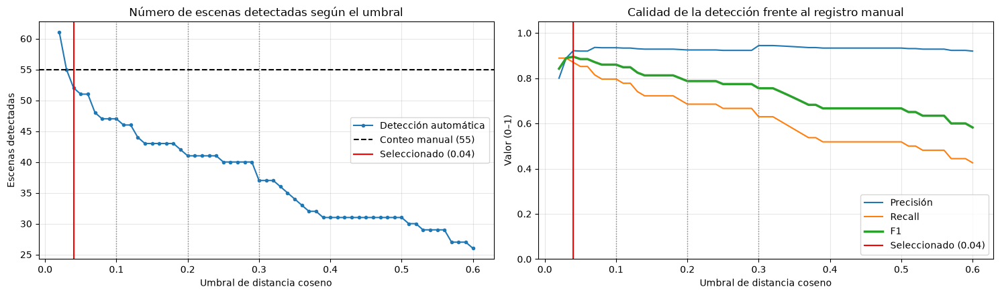

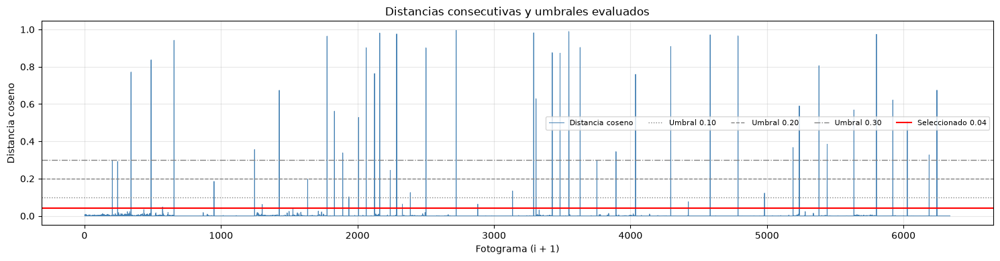

**Umbral seleccionado: 0.04** (máximo F1 del barrido).

- Escenas detectadas: 52 (manual: 55).
- Precisión 0.92, recall 0.87, F1 0.90; 4 falsos cambios y 7 cambios no detectados.
- Umbral estadístico de referencia (media + 3σ): 0.185.

In [16]:
UMBRAL_FORZADO = None   # escribir un valor (p. ej. 0.20) solo si el equipo decide fijarlo manualmente

barrido = np.round(np.arange(0.02, 0.601, 0.01), 2)
metricas = [comparar_con_manual(detectar_cambios(distancias, u)) for u in barrido]
n_escenas = np.array([m["vp"] + m["fp"] + 1 for m in metricas])
f1s = np.array([m["f1"] for m in metricas])

# Empates: primero menor diferencia de conteo; luego el umbral central de la meseta,
# que deja el mayor margen ante pequeñas variaciones de las distancias.
f1_max = f1s.round(4).max()
empatados = [k for k in range(len(barrido)) if f1s[k].round(4) == f1_max]
dif_min = min(abs(n_escenas[k] - escenas_manual) for k in empatados)
empatados = [k for k in empatados if abs(n_escenas[k] - escenas_manual) == dif_min]
mejor = empatados[len(empatados) // 2]
UMBRAL_SELECCIONADO = float(UMBRAL_FORZADO) if UMBRAL_FORZADO is not None else float(barrido[mejor])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
ax1.plot(barrido, n_escenas, marker=".", label="Detección automática")
ax1.axhline(escenas_manual, color="black", ls="--", label=f"Conteo manual ({escenas_manual})")
ax1.set_title("Número de escenas detectadas según el umbral")
ax1.set_xlabel("Umbral de distancia coseno"); ax1.set_ylabel("Escenas detectadas")
ax1.yaxis.get_major_locator().set_params(integer=True)
ax2.plot(barrido, [m["precision"] for m in metricas], label="Precisión")
ax2.plot(barrido, [m["recall"] for m in metricas], label="Recall")
ax2.plot(barrido, f1s, lw=2.5, label="F1")
ax2.set_title("Calidad de la detección frente al registro manual")
ax2.set_xlabel("Umbral de distancia coseno"); ax2.set_ylabel("Valor (0–1)"); ax2.set_ylim(0, 1.05)
for ax in (ax1, ax2):
    for u in UMBRALES[:3]:
        ax.axvline(u, color="gray", ls=":", lw=1)
    ax.axvline(UMBRAL_SELECCIONADO, color="red", lw=1.5, label=f"Seleccionado ({UMBRAL_SELECCIONADO:.2f})")
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(np.arange(1, contador), distancias, lw=0.7, color="steelblue", label="Distancia coseno")
for u, estilo in zip(UMBRALES[:3], [":", "--", "-."]):
    ax.axhline(u, color="gray", ls=estilo, lw=1, label=f"Umbral {u:.2f}")
ax.axhline(UMBRAL_SELECCIONADO, color="red", lw=1.5, label=f"Seleccionado {UMBRAL_SELECCIONADO:.2f}")
ax.set_title("Distancias consecutivas y umbrales evaluados")
ax.set_xlabel("Fotograma (i + 1)"); ax.set_ylabel("Distancia coseno"); ax.grid(alpha=0.3); ax.legend(ncol=5, fontsize=8)
plt.tight_layout(); plt.show()

r_sel = comparar_con_manual(detectar_cambios(distancias, UMBRAL_SELECCIONADO))
display(Markdown(
    f"**Umbral seleccionado: {UMBRAL_SELECCIONADO:.2f}** "
    f"({'fijado manualmente por el equipo' if UMBRAL_FORZADO is not None else 'máximo F1 del barrido'}).\n\n"
    f"- Escenas detectadas: {r_sel['vp'] + r_sel['fp'] + 1} (manual: {escenas_manual}).\n"
    f"- Precisión {r_sel['precision']:.2f}, recall {r_sel['recall']:.2f}, F1 {r_sel['f1']:.2f}; "
    f"{r_sel['fp']} falsos cambios y {r_sel['fn']} cambios no detectados.\n"
    f"- Umbral estadístico de referencia (media + 3σ): {umbral_estadistico:.3f}."))

#### Justificación del umbral elegido

- **Umbrales muy bajos (0,02):** se sobredetectan escenas (61 frente a 55 manuales), con 12 falsos cambios y precisión 0,80. Pequeños movimientos de cámara o de iluminación ya superan el umbral.
- **Umbral 0,03:** el número de escenas coincide exactamente con el manual (55), pero con 6 falsos cambios y 6 cortes no detectados: acertar el conteo no implica acertar los cortes.
- **Umbrales sugeridos (0,10; 0,20; 0,30) y estadístico (0,185):** los falsos cambios se mantienen en 2–3 y la precisión ronda 0,93, pero los cortes no detectados aumentan (11, 17 y 20; 15 con el estadístico). Muchos cortes del video ocurren entre planos de fútbol sobre césped verde; como el vector usa solo el matiz, sus histogramas son parecidos y la distancia coseno queda por debajo de 0,1.
- **Umbral seleccionado (0,04):** maximiza el F1 (0,90), con precisión 0,92 y recall 0,87. Detecta 52 escenas, con 4 falsos cambios y 7 cortes no detectados. Es el mejor equilibrio: bajarlo agrega falsos cambios y subirlo solo hace perder cortes reales.
- **Comparación con el umbral estadístico (media + 3σ = 0,185):** es bastante más alto que el elegido. La distribución de distancias tiene una cola larga (los cortes muy marcados llegan a ~1,0), lo que eleva la desviación estándar, mientras que el 99 % de las distancias está por debajo de 0,04. Por eso la regla media + 3σ es demasiado conservadora para este video.

### 3.6. Detección automática de escenas

Con el umbral seleccionado se aplican las mismas reglas de 3.5 (umbral + separación mínima). Cada cambio marca el **primer fotograma** de una escena nueva; la escena `k` abarca el intervalo `[inicio_k, inicio_{k+1})`, igual que en la tabla manual, por lo que no hay huecos ni solapamientos. La última columna indica si el cambio coincide (±0,75 s) con un cambio del registro manual.

Umbral utilizado: 0.04
Cambios detectados: 51
Número total de escenas detectadas automáticamente: 52


| Cambio | Fotograma | Tiempo | Distancia | ¿Coincide con el manual? |
|---:|---:|:---:|---:|:---:|
| 1 | 204 | 00:06.8 | 0.298 | No (falso cambio) |
| 2 | 243 | 00:08.1 | 0.292 | Sí |
| 3 | 341 | 00:11.4 | 0.772 | Sí |
| 4 | 488 | 00:16.3 | 0.837 | Sí |
| 5 | 572 | 00:19.1 | 0.048 | Sí |
| 6 | 656 | 00:21.9 | 0.942 | Sí |
| 7 | 949 | 00:31.6 | 0.185 | Sí |
| 8 | 1246 | 00:41.5 | 0.356 | Sí |
| 9 | 1302 | 00:43.4 | 0.062 | No (falso cambio) |
| 10 | 1427 | 00:47.6 | 0.674 | Sí |
| 11 | 1635 | 00:54.5 | 0.196 | Sí |
| 12 | 1777 | 00:59.2 | 0.964 | Sí |
| 13 | 1831 | 01:01.0 | 0.562 | Sí |
| 14 | 1892 | 01:03.1 | 0.338 | Sí |
| 15 | 1937 | 01:04.6 | 0.102 | Sí |
| 16 | 2008 | 01:06.9 | 0.529 | Sí |
| 17 | 2064 | 01:08.8 | 0.902 | Sí |
| 18 | 2125 | 01:10.8 | 0.764 | Sí |
| 19 | 2163 | 01:12.1 | 0.981 | Sí |
| 20 | 2240 | 01:14.7 | 0.244 | Sí |
| 21 | 2287 | 01:16.2 | 0.976 | Sí |
| 22 | 2329 | 01:17.6 | 0.063 | Sí |
| 23 | 2387 | 01:19.6 | 0.125 | Sí |
| 24 | 2502 | 01:23.4 | 0.901 | Sí |
| 25 | 2723 | 01:30.8 | 0.996 | Sí |
| 26 | 2881 | 01:36.0 | 0.063 | Sí |
| 27 | 3136 | 01:44.5 | 0.134 | Sí |
| 28 | 3291 | 01:49.7 | 0.982 | Sí |
| 29 | 3308 | 01:50.3 | 0.628 | Sí |
| 30 | 3427 | 01:54.2 | 0.876 | Sí |
| 31 | 3484 | 01:56.1 | 0.872 | Sí |
| 32 | 3548 | 01:58.3 | 0.989 | No (falso cambio) |
| 33 | 3631 | 02:01.0 | 0.904 | Sí |
| 34 | 3754 | 02:05.1 | 0.295 | Sí |
| 35 | 3894 | 02:09.8 | 0.345 | Sí |
| 36 | 4037 | 02:14.6 | 0.760 | Sí |
| 37 | 4295 | 02:23.2 | 0.909 | Sí |
| 38 | 4424 | 02:27.5 | 0.076 | Sí |
| 39 | 4584 | 02:32.8 | 0.972 | Sí |
| 40 | 4788 | 02:39.6 | 0.965 | Sí |
| 41 | 4982 | 02:46.1 | 0.122 | Sí |
| 42 | 5191 | 02:53.0 | 0.367 | Sí |
| 43 | 5237 | 02:54.6 | 0.590 | Sí |
| 44 | 5381 | 02:59.4 | 0.806 | Sí |
| 45 | 5441 | 03:01.4 | 0.384 | Sí |
| 46 | 5637 | 03:07.9 | 0.569 | Sí |
| 47 | 5802 | 03:13.4 | 0.974 | Sí |
| 48 | 5922 | 03:17.4 | 0.621 | Sí |
| 49 | 6028 | 03:20.9 | 0.506 | Sí |
| 50 | 6188 | 03:26.3 | 0.327 | Sí |
| 51 | 6245 | 03:28.2 | 0.674 | No (falso cambio) |

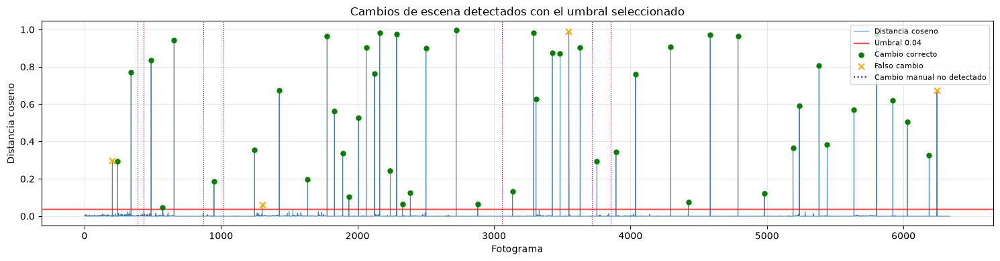

Tabla exportada: escenas_automaticas.csv


In [17]:
cambios_auto = detectar_cambios(distancias, UMBRAL_SELECCIONADO)
evaluacion = comparar_con_manual(cambios_auto)
falsos = set(evaluacion["falsos"])

inicios_auto = [0] + cambios_auto.tolist()
finales_auto = cambios_auto.tolist() + [contador]
escenas_auto = [{"escena": k + 1, "inicio_frame": a, "fin_frame": b,
                 "tiempo_inicial": tiempo_texto(a / fps), "tiempo_final": tiempo_texto(b / fps)}
                for k, (a, b) in enumerate(zip(inicios_auto, finales_auto))]
assert sum(e["fin_frame"] - e["inicio_frame"] for e in escenas_auto) == contador

print(f"Umbral utilizado: {UMBRAL_SELECCIONADO:.2f}")
print(f"Cambios detectados: {len(cambios_auto)}")
print(f"Número total de escenas detectadas automáticamente: {len(escenas_auto)}")

lineas = ["| Cambio | Fotograma | Tiempo | Distancia | ¿Coincide con el manual? |", "|---:|---:|:---:|---:|:---:|"]
for n, f in enumerate(cambios_auto, start=1):
    lineas.append(f"| {n} | {f} | {tiempo_texto(f / fps)} | {distancias[f - 1]:.3f} | {'No (falso cambio)' if f in falsos else 'Sí'} |")
display(Markdown("\n".join(lineas)))

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(np.arange(1, contador), distancias, lw=0.7, color="steelblue", label="Distancia coseno")
ax.axhline(UMBRAL_SELECCIONADO, color="red", lw=1, label=f"Umbral {UMBRAL_SELECCIONADO:.2f}")
ok = [f for f in cambios_auto if f not in falsos]
ax.scatter(ok, distancias[np.array(ok, dtype=int) - 1], color="green", zorder=3, s=25, label="Cambio correcto")
if falsos:
    fl = sorted(falsos)
    ax.scatter(fl, distancias[np.array(fl) - 1], color="orange", marker="x", zorder=3, s=40, label="Falso cambio")
for f in cambios_manual[evaluacion["omitidos"]]:
    ax.axvline(f, color="purple", ls=":", lw=0.8)
ax.plot([], [], color="purple", ls=":", label="Cambio manual no detectado")
ax.set_title("Cambios de escena detectados con el umbral seleccionado")
ax.set_xlabel("Fotograma"); ax.set_ylabel("Distancia coseno"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

with (RAIZ / "escenas_automaticas.csv").open("w", encoding="utf-8-sig", newline="") as archivo:
    escritor = csv.DictWriter(archivo, fieldnames=list(escenas_auto[0]))
    escritor.writeheader()
    escritor.writerows(escenas_auto)
print("Tabla exportada: escenas_automaticas.csv")

### 3.7. Obtención de fotogramas representativos

Elegir simplemente el primer fotograma de cada escena es arriesgado: suele estar en plena transición (desenfoque, fundido, restos del plano anterior). Elegir el fotograma central es mejor, pero no garantiza que sea *típico* de la escena.

Se usa el **medoide en el espacio de características**: se calcula el vector promedio de la escena y se elige el fotograma cuya distancia coseno a ese promedio es mínima. Es el fotograma que mejor resume la apariencia global de la escena. Se descartan los 3 fotogramas de cada borde (0,1 s) cuando la escena es suficientemente larga, para evitar transiciones. El tiempo mostrado es `fotograma / fps`.

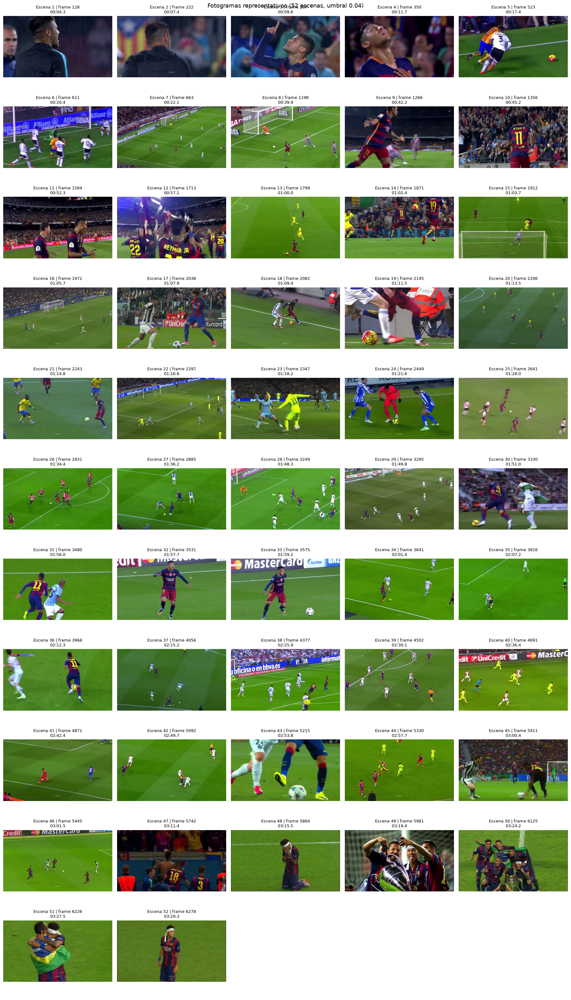

Imágenes guardadas en: fotogramas_representativos/


In [18]:
MARGEN_BORDE = 3
CARPETA_REPRESENTATIVOS = RAIZ / "fotogramas_representativos"
CARPETA_REPRESENTATIVOS.mkdir(exist_ok=True)
for ruta in CARPETA_REPRESENTATIVOS.glob("escena_*.jpg"):
    ruta.unlink()          # evita mezclar resultados de un umbral anterior

def medoide(a, b):
    if b - a > 2 * MARGEN_BORDE + 1:
        a, b = a + MARGEN_BORDE, b - MARGEN_BORDE
    bloque = caracteristicas[a:b]
    centro = bloque.mean(axis=0)
    sim = bloque @ centro / (np.linalg.norm(bloque, axis=1) * np.linalg.norm(centro) + 1e-12)
    return a + int(np.argmax(sim))

representativos = []
for e in escenas_auto:
    f = medoide(e["inicio_frame"], e["fin_frame"])
    imagen = cv2.imread(str(CARPETA_FRAMES / f"frame_{f:05d}.jpg"))
    if imagen is None:
        raise RuntimeError(f"No se pudo leer el fotograma representativo {f}.")
    ruta = CARPETA_REPRESENTATIVOS / f"escena_{e['escena']:03d}_frame_{f:05d}.jpg"
    cv2.imwrite(str(ruta), imagen, [cv2.IMWRITE_JPEG_QUALITY, 95])
    e["frame_representativo"] = f
    representativos.append({"escena": e["escena"], "fotograma": f, "tiempo": tiempo_texto(f / fps),
                            "imagen": cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)})

COLUMNAS_REP = 5
filas_rep = math.ceil(len(representativos) / COLUMNAS_REP)
fig, ejes = plt.subplots(filas_rep, COLUMNAS_REP, figsize=(18, 2.9 * filas_rep), squeeze=False)
for eje in ejes.flat:
    eje.axis("off")
for eje, r in zip(ejes.flat, representativos):
    eje.imshow(r["imagen"])
    eje.set_title(f"Escena {r['escena']} | frame {r['fotograma']}\n{r['tiempo']}", fontsize=9)
fig.suptitle(f"Fotogramas representativos ({len(representativos)} escenas, umbral {UMBRAL_SELECCIONADO:.2f})", fontsize=13)
plt.tight_layout(); plt.show()
print(f"Imágenes guardadas en: {CARPETA_REPRESENTATIVOS.name}/")

#### Interpretación de los fotogramas representativos

Con el umbral 0,04 se obtuvieron **52 escenas** (55 en el registro manual), y los fotogramas representativos **permiten reconocer las partes principales del video**, en el mismo orden en que aparecen:

- **Inicio (≈ 00:00–00:16):** planos de Neymar en el calentamiento y primeros planos mirando al cielo. El algoritmo los separa cuando cambian el fondo, la iluminación o el encuadre, pero no separa primeros planos consecutivos muy parecidos.
- **Parte central (≈ 00:16–03:07):** regates y jugadas contra rivales con uniformes distintos. Es la parte más difícil: casi todos los fotogramas comparten el **césped verde**, así que varios representativos consecutivos se parecen a simple vista aunque correspondan a jugadas diferentes.
- **Final (≈ 03:07–03:31):** celebraciones, la copa de Champions League y el abrazo con la bandera de Brasil. Sus colores son muy distintos al campo de juego, por eso se detectan con distancias altas.

La selección por medoide evita fotogramas borrosos o de transición. El análisis detallado de aciertos, falsos cambios y cortes no detectados se presenta en el **punto 4**.

### 3.8. Generación de GIF resumen

Los fotogramas representativos se reducen a 480 × 270 píxeles (misma relación 16:9) para que el archivo sea liviano, y a cada uno se le añade una franja con el número de escena, el fotograma y el tiempo. Cada imagen se muestra 0,8 s, suficiente para reconocerla sin que el resumen se alargue demasiado; el GIF se repite indefinidamente (`loop=0`).

Pillow convierte cada imagen a una paleta de 256 colores, limitación propia del formato GIF; por eso puede notarse un leve bandeado en degradados. En Colab, descargar `escenas.gif` desde el panel de archivos antes de cerrar la sesión.

escenas.gif: 52 cuadros, 41.6 s, 3.53 MiB


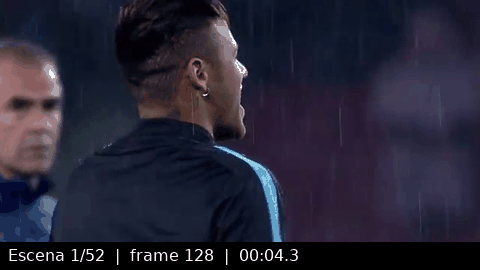

In [19]:
from PIL import ImageFont
from matplotlib import font_manager

RUTA_GIF = RAIZ / "escenas.gif"
TAMANO_GIF = (480, 270)
DURACION_MS = 800
fuente = ImageFont.truetype(font_manager.findfont("DejaVu Sans"), 16)

cuadros = []
for r in representativos:
    cuadro = PILImage.fromarray(r["imagen"]).resize(TAMANO_GIF, PILImage.LANCZOS)
    dibujo = ImageDraw.Draw(cuadro)
    dibujo.rectangle([0, TAMANO_GIF[1] - 28, TAMANO_GIF[0], TAMANO_GIF[1]], fill="black")
    dibujo.text((8, TAMANO_GIF[1] - 24),
                f"Escena {r['escena']}/{len(representativos)}  |  frame {r['fotograma']}  |  {r['tiempo']}",
                fill="white", font=fuente)
    cuadros.append(cuadro)

cuadros[0].save(RUTA_GIF, save_all=True, append_images=cuadros[1:], duration=DURACION_MS, loop=0, optimize=True)

with PILImage.open(RUTA_GIF) as gif:
    if gif.n_frames != len(representativos):
        raise RuntimeError("El GIF no contiene un cuadro por escena.")
print(f"{RUTA_GIF.name}: {len(cuadros)} cuadros, {len(cuadros) * DURACION_MS / 1000:.1f} s, "
      f"{RUTA_GIF.stat().st_size / 1024**2:.2f} MiB")
display(Image(filename=str(RUTA_GIF)))

## 4. Comparación entre detección manual y automática

En esta sección se compara el **registro manual** (punto 2) con la **detección automática** (punto 3.6, con el umbral seleccionado en 3.5).

Se usan las mismas reglas definidas en 3.5:
- Un cambio automático es **correcto** si hay un cambio manual a ±0,75 s.
- Un cambio automático sin pareja manual es un **falso cambio** (el algoritmo "corta" donde no hay escena nueva).
- Un cambio manual sin pareja automática es un **cambio no detectado**.

### 4.1. Tabla comparativa

In [20]:
n_manual = len(escenas)        # escenas del registro manual (punto 2)
n_auto = len(escenas_auto)     # escenas detectadas automáticamente (punto 3.6)

tabla = f"""| Método | Número de escenas |
|---|---:|
| Conteo manual | {n_manual} |
| Detección automática (umbral {UMBRAL_SELECCIONADO:.2f}) | {n_auto} |
| Diferencia | {abs(n_manual - n_auto)} |
"""
display(Markdown(tabla))

detalle = f"""| Resultado de la comparación | Cantidad |
|---|---:|
| Cambios correctamente detectados | {evaluacion['vp']} |
| Falsos cambios (detectados, pero no son escena nueva) | {evaluacion['fp']} |
| Cambios reales no detectados | {evaluacion['fn']} |
| Precisión = correctos / detectados | {evaluacion['precision']:.2f} |
| Recall = correctos / cambios manuales | {evaluacion['recall']:.2f} |
"""
display(Markdown(detalle))

| Método | Número de escenas |
|---|---:|
| Conteo manual | 55 |
| Detección automática (umbral 0.04) | 52 |
| Diferencia | 3 |


| Resultado de la comparación | Cantidad |
|---|---:|
| Cambios correctamente detectados | 47 |
| Falsos cambios (detectados, pero no son escena nueva) | 4 |
| Cambios reales no detectados | 7 |
| Precisión = correctos / detectados | 0.92 |
| Recall = correctos / cambios manuales | 0.87 |


### 4.2. Ejemplos de cada caso

Para cada tipo de resultado se listan ejemplos con su tiempo y su distancia coseno, y luego se muestran los dos fotogramas a cada lado del cambio (**antes** y **después**) para poder ver qué ocurrió.

- **Correctos:** cambio automático y la escena manual con la que coincide.
- **Falsos cambios:** cambio automático sin escena manual cercana.
- **No detectados:** escena manual cuyo inicio no fue encontrado. Como el tiempo manual es aproximado, se busca el pico de distancia más alto en ±0,75 s alrededor y se muestra ese punto: su distancia quedó **por debajo del umbral**.

In [21]:
correctos = [f for f in cambios_auto if f not in falsos]
falsos_lista = sorted(falsos)
omitidos = evaluacion["omitidos"]   # índices de cambios manuales no detectados

print(f"ESCENAS CORRECTAMENTE DETECTADAS ({len(correctos)}). Ejemplos:")
for f in correctos[:5]:
    im = np.argmin(np.abs(cambios_manual - f))   # cambio manual más cercano
    e = escenas[im + 1]
    print(f"  {tiempo_texto(f / fps)} (frame {f}, d={distancias[f - 1]:.3f})  ->  manual {e['tiempo_inicial']}: {e['descripcion']}")

print(f"\nFALSOS CAMBIOS ({len(falsos_lista)}):")
for f in falsos_lista:
    print(f"  {tiempo_texto(f / fps)} (frame {f}, d={distancias[f - 1]:.3f})")

def pico_cercano(frame_manual):
    """Fotograma (i + 1) con la mayor distancia en ±TOLERANCIA alrededor de un cambio manual."""
    inicio = max(0, frame_manual - 1 - TOLERANCIA)
    ventana = distancias[inicio: frame_manual + TOLERANCIA]
    return inicio + int(np.argmax(ventana)) + 1

print(f"\nCAMBIOS REALES NO DETECTADOS ({len(omitidos)}):")
for im in omitidos:
    e = escenas[im + 1]
    f = pico_cercano(cambios_manual[im])
    print(f"  Escena {e['escena']} ({e['tiempo_inicial']}): {e['descripcion']}  "
          f"-> pico más alto cercano d={distancias[f - 1]:.3f} (umbral {UMBRAL_SELECCIONADO:.2f})")

ESCENAS CORRECTAMENTE DETECTADAS (47). Ejemplos:
  00:08.1 (frame 243, d=0.292)  ->  manual 00:08.5: Neymar con camiseta del Barcelona, mirando y señalando hacia arriba.
  00:11.4 (frame 341, d=0.772)  ->  manual 00:11.5: Primer plano de Neymar mirando al cielo.
  00:16.3 (frame 488, d=0.837)  ->  manual 00:16.5: Regate junto a la banda con camiseta amarilla y roja, frente a un defensor de blanco.
  00:19.1 (frame 572, d=0.048)  ->  manual 00:19.5: Otro plano de la misma acción cerca del área y la portería.
  00:21.9 (frame 656, d=0.942)  ->  manual 00:22.0: Plano general de un ataque del Barcelona ante rivales de blanco y celeste.

FALSOS CAMBIOS (4):
  00:06.8 (frame 204, d=0.298)
  00:43.4 (frame 1302, d=0.062)
  01:58.3 (frame 3548, d=0.989)
  03:28.2 (frame 6245, d=0.674)

CAMBIOS REALES NO DETECTADOS (7):
  Escena 4 (00:13.0): Primer plano de Neymar mirando al frente y bajando la mirada.  -> pico más alto cercano d=0.007 (umbral 0.04)
  Escena 5 (00:14.5): Neymar se lleva las man

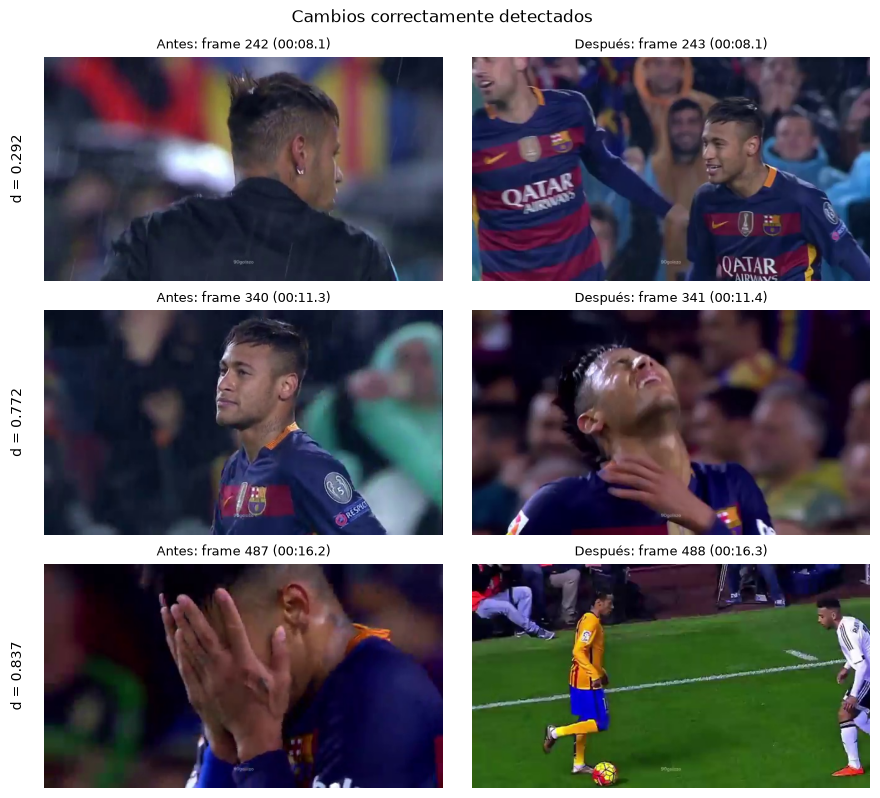

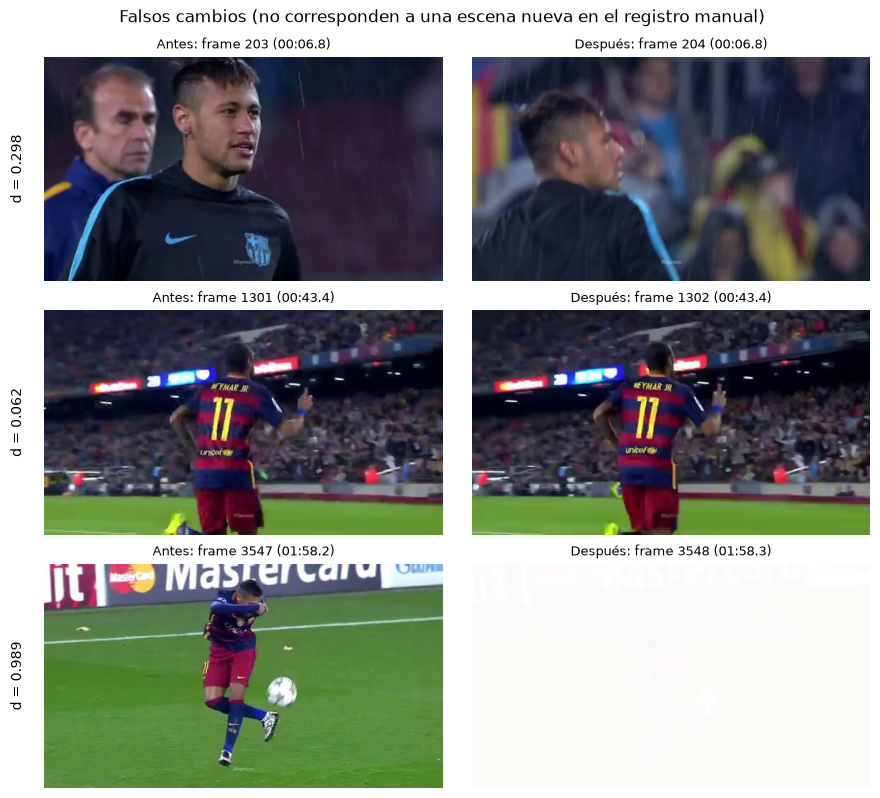

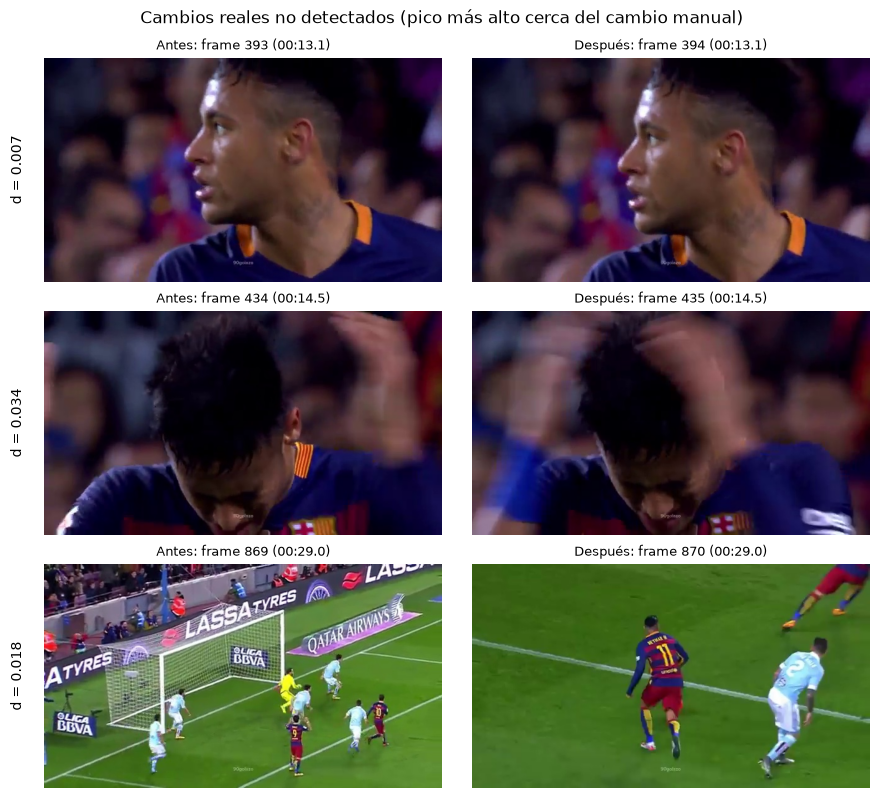

In [22]:
def mostrar_cortes(frames_cambio, titulo):
    """Muestra el fotograma anterior y el posterior de cada cambio (una fila por cambio)."""
    if len(frames_cambio) == 0:
        print(f"{titulo}: no hay ejemplos.")
        return
    fig, ejes = plt.subplots(len(frames_cambio), 2, figsize=(9, 2.7 * len(frames_cambio)), squeeze=False)
    for fila, f in enumerate(frames_cambio):
        for col, indice in enumerate([f - 1, f]):
            imagen = cv2.imread(str(CARPETA_FRAMES / f"frame_{indice:05d}.jpg"))
            ejes[fila, col].imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
            ejes[fila, col].set_title(f"{'Antes' if col == 0 else 'Después'}: frame {indice} ({tiempo_texto(indice / fps)})", fontsize=9)
            ejes[fila, col].axis("off")
        ejes[fila, 0].text(-0.05, 0.5, f"d = {distancias[f - 1]:.3f}", transform=ejes[fila, 0].transAxes,
                           rotation=90, va="center", ha="right", fontsize=10)
    fig.suptitle(titulo, fontsize=12)
    plt.tight_layout()
    plt.show()

mostrar_cortes(correctos[:3], "Cambios correctamente detectados")
mostrar_cortes(falsos_lista[:3], "Falsos cambios (no corresponden a una escena nueva en el registro manual)")
mostrar_cortes([pico_cercano(cambios_manual[im]) for im in omitidos[:3]],
               "Cambios reales no detectados (pico más alto cerca del cambio manual)")

### 4.3. Distancias de cada tipo de resultado

Un diagrama de caja resume las distancias coseno de los cambios correctos, de los falsos cambios y del pico más alto cerca de cada cambio no detectado. Permite ver si los errores están cerca del umbral (se podrían corregir moviéndolo) o lejos (son un límite del método).

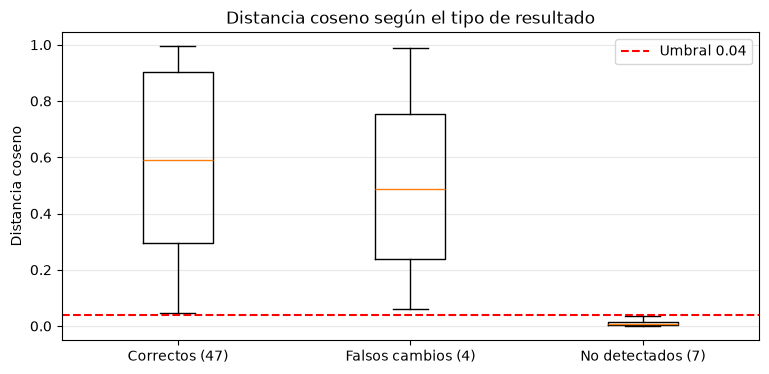

Mediana de distancia - correctos: 0.590
Mediana de distancia - falsos cambios: 0.486
Mediana del pico cercano - no detectados: 0.007


In [23]:
# Comparación de las distancias de cada grupo: ¿qué tan lejos quedaron del umbral?
d_correctos = [distancias[f - 1] for f in correctos]
d_falsos = [distancias[f - 1] for f in falsos_lista]
d_omitidos = [distancias[pico_cercano(cambios_manual[im]) - 1] for im in omitidos]

plt.figure(figsize=(9, 4))
plt.boxplot([d_correctos, d_falsos, d_omitidos], showfliers=True)
plt.xticks([1, 2, 3], [f"Correctos ({len(d_correctos)})", f"Falsos cambios ({len(d_falsos)})", f"No detectados ({len(d_omitidos)})"])
plt.axhline(UMBRAL_SELECCIONADO, color="red", ls="--", label=f"Umbral {UMBRAL_SELECCIONADO:.2f}")
plt.title("Distancia coseno según el tipo de resultado")
plt.ylabel("Distancia coseno")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.show()

print(f"Mediana de distancia - correctos: {np.median(d_correctos):.3f}")
if d_falsos:
    print(f"Mediana de distancia - falsos cambios: {np.median(d_falsos):.3f}")
if d_omitidos:
    print(f"Mediana del pico cercano - no detectados: {np.median(d_omitidos):.3f}")

### 4.4. Análisis de los resultados y posibles causas

**Resumen.** El registro manual tiene **55 escenas** y la detección automática con umbral 0,04 encontró **52** (diferencia de 3). Pero la diferencia en el conteo esconde errores que se compensan: de los 51 cambios automáticos, **47 son correctos**, **4 son falsos cambios**, y además hay **7 cambios reales que no se detectaron** (51 − 4 + 7 = 54 cambios manuales). Por eso no basta comparar el número de escenas: hay que revisar *dónde* está cada corte.

**Escenas correctamente detectadas (47).** Son la gran mayoría. Los ejemplos más claros son los cortes entre planos con **colores muy distintos**: de un primer plano de Neymar (fondo oscuro, piel, camiseta azul) a un plano general del campo (casi todo verde), como en 00:16,3 (d = 0,837) o 00:21,9 (d = 0,942). Ahí el histograma de matiz cambia casi por completo y la distancia coseno se acerca a 1. La mediana de las distancias de los cambios correctos es ≈ 0,59, muy por encima del umbral.

**Falsos cambios (4).** Al revisar los fotogramas de antes y después se ve que no todos son errores del algoritmo:
- **01:58,3 (d = 0,989):** es un **destello blanco** de transición entre dos clips. El blanco no tiene matiz, así que todo el histograma se concentra en un solo bin y la distancia es casi 1. Después del destello empieza otro clip de Neymar, por lo que en realidad es un corte que el registro manual no anotó.
- **03:28,2 (d = 0,674):** se pasa del abrazo con la bandera de Brasil a Neymar caminando solo. Es un **corte real**; en la tabla manual ambos planos quedaron en la misma escena (la descripción dice "abraza… y luego saluda").
- **00:06,8 (d = 0,298):** dentro del calentamiento, la cámara pasa de Neymar de frente a Neymar de espaldas con la tribuna desenfocada. Es un cambio de plano que el registro manual no separó.
- **00:43,4 (d = 0,062):** durante la celebración, los dos fotogramas son prácticamente iguales. Es un **falso cambio verdadero**: un pequeño salto de la imagen o de la iluminación superó un umbral tan bajo como 0,04.

Es decir, 3 de los 4 "falsos cambios" son cortes reales que el registro manual omitió porque se hizo revisando imágenes cada 0,5 s. Solo uno es un error real del método.

**Cambios reales no detectados (7).** Todos tienen un pico de distancia muy bajo (mediana ≈ 0,007), lejos del umbral. Hay dos tipos:
- **Cortes entre planos de fútbol sobre césped** (00:29,0, 01:42,0, 02:04,0, 02:08,5). En 00:29,0 se pasa de un plano general del arco a un plano cercano del regate, y la distancia es solo 0,018. Los dos planos están dominados por el **verde del césped**, y como el vector usa solo el **matiz (H)**, ambos histogramas son casi iguales aunque el encuadre sea completamente distinto. El histograma no guarda información de *dónde* están los colores ni de la forma de los objetos.
- **Primeros planos consecutivos de Neymar** (00:13,0 y 00:14,5). Las imágenes antes y después muestran la misma cara, el mismo fondo y la misma camiseta. La distancia es casi 0, por lo que, si hubo un corte, el método no lo puede ver con color. En estos casos también es posible que el registro manual haya separado demasiado.

**Conclusión del análisis.** El diagrama de caja de 4.3 muestra que los no detectados quedan **muy por debajo** del umbral (≈ 0,007), mientras que los falsos cambios quedan **por encima** (≈ 0,49). Esto significa que **no existe un umbral que corrija ambos errores a la vez**: bajarlo hasta 0,007 llenaría el video de falsos cambios por el movimiento normal de la cámara (el 99 % de las distancias están por debajo de 0,04). Los errores restantes no son un problema del umbral, sino de lo que el vector de características puede representar.

## 5. Conclusiones

1. **La detección automática fue cercana al análisis manual, pero el conteo de escenas por sí solo engaña.** Se detectaron 52 escenas frente a 55 manuales (diferencia de 3) y el 92 % de los cortes detectados coincide con un corte manual (precisión 0,92), encontrando el 87 % de los cortes reales (recall 0,87). Sin embargo, con el umbral 0,03 el conteo coincide *exactamente* (55 escenas) y aun así hay 6 falsos cambios y 6 omisiones. Por eso evaluamos con correspondencia de tiempos (precisión, recall y F1) y no solo con la cantidad de escenas.

2. **El umbral tiene una influencia muy fuerte, y el valor óptimo para este video es mucho menor que los sugeridos.** Con 0,10; 0,20 y 0,30 se detectaron 47, 41 y 37 escenas: cada aumento hace perder cortes reales sin reducir casi los falsos cambios (se mantienen en 2–3). La razón está en el histograma de distancias: el 99 % de los pares consecutivos tiene una distancia menor a 0,04 (la mediana es ≈ 0,00006), así que incluso un valor pequeño ya separa los cortes del movimiento normal. El umbral elegido, 0,04, maximiza el F1 (0,90). Por debajo (0,02) aparecen 12 falsos cambios; por encima solo se pierden cortes. El umbral estadístico (media + 3σ = 0,185) resultó demasiado alto, porque los cortes muy marcados (d ≈ 1) aumentan la desviación estándar.

3. **Los errores se explican por el tipo de característica utilizada: un histograma de matiz solo "ve" colores.** Falla cuando dos planos distintos tienen los mismos colores (cortes entre planos de fútbol sobre el césped verde, o primeros planos seguidos de Neymar) y genera picos cuando cambian los colores sin cambiar la escena o en efectos de edición (el destello blanco de 01:58,3). Además, al revisar los "falsos cambios" encontramos que 3 de 4 eran cortes reales que nuestro registro manual no había anotado: **la referencia manual también tiene errores**, sobre todo en cortes muy rápidos.

4. **Mejoras posibles al procedimiento.**
   - Usar un histograma de **H, S y V** (no solo matiz) para distinguir mejor el blanco, el negro y la iluminación.
   - Calcular histogramas **por regiones** de la imagen (por ejemplo, una cuadrícula de 3 × 3) para captar *dónde* están los colores y así diferenciar un plano general de un plano cercano sobre el césped.
   - Usar características de una **red neuronal preentrenada** (por ejemplo, ResNet), que describen formas y objetos además del color.
   - Ignorar picos aislados de uno o dos fotogramas, como los destellos, comparando el fotograma con varios anteriores y posteriores.
   - Revisar el registro manual reproduciendo el video a velocidad reducida, para que la referencia sea más confiable.